# Caso Práctico de Negocio: recompra a 60 días

**Objetivo:** identificar a los clientes con alta probabilidad de realizar una nueva orden en los 60 días siguientes a su primera compra.

**Estructura del notebook**

| Parte | Sección | Contenido |
|---|---|---|
| SQL en BigQuery | 1 | Exploración, perfilado y controles de calidad |
| | 2 | Definición de la variable objetivo |
| | 3 | Ingeniería de variables y prevención de fuga de información |
| | 4 | Tabla analítica final `customer_model`, optimización y Snowflake |
| Python | 5 | Configuración, carga y validación automatizada de datos |
| | 6 | Análisis exploratorio orientado al modelo y al negocio |
| | 7 | Diseño de la evaluación temporal |
| | 8 | Modelado: referencias, candidatos y selección |
| | 9 | Evaluación final en el periodo de prueba |
| | 10 | Pipeline automatizado: reentrenamiento y predicciones |
| | 11 | Conclusiones, limitaciones y recomendaciones |
| Arquitectura cloud | 12 | Diseño en AWS: carga, programación, predicciones, monitoreo, GitHub y Snowflake |

## Parte 1. Preparación de datos en BigQuery

**Nota sobre la ejecución y reproducibilidad:** las consultas SQL se desarrollaron y ejecutaron en Google BigQuery. En este notebook se muestran como bloques de texto, para que el notebook pueda ejecutarse de principio a fin (*Run All*) sin acceso al proyecto. También están disponibles como archivos en la carpeta `SQL/`.

**Flujo de trabajo:**

1. Las consultas se ejecutan en BigQuery y generan la tabla analítica `customer_model`.
2. La tabla se exporta como CSV a `data/customer_model.csv`. El tiempo hasta la recompra se exporta a `data/tiempo_entre_compras.csv`.
3. La parte de Python (secciones 5 a 11) parte de esos archivos y se ejecuta de principio a fin sin pasos manuales: validación, análisis, modelado y predicciones.

Cada apartado presenta primero los resultados y su interpretación, y a continuación la consulta que los genera.

### 1. Exploración y perfilado de datos

#### 1.1. Objetivo

Evaluar la estructura, integridad y calidad inicial de las tablas del dataset de e-commerce para construir una base analítica orientada a predecir la recompra durante los 60 días posteriores a la primera compra.

#### 1.2. Integridad de identificadores

Se analizaron de manera preliminar las siete tablas del dataset mediante consultas SQL en BigQuery:

| Tabla | Registros | Claves nulas | Claves duplicadas |
|---|---:|---:|---:|
| orders | 124596 | 0 | 0 |
| order_items | 180670 | 0 | 0 |
| users | 100000 | 0 | 0 |
| products | 29120 | 0 | 0 |
| events | 2420763 | 0 | 0 |
| inventory_items | 487604 | 0 | 0 |
| distribution_centers | 10 | 0 | 0 |

En una primera instancia no se identificaron valores nulos ni duplicados en las claves identificadoras evaluadas. La integridad referencial entre tablas se verifica en el apartado 1.6.

```sql
-- Perfil inicial de claves por tabla

SELECT
  'orders' AS tabla,
  COUNT(*) AS total_filas,
  COUNTIF(order_id IS NULL) AS claves_nulas,
  COUNT(*) - COUNT(DISTINCT order_id)
    - COUNTIF(order_id IS NULL) AS filas_con_clave_repetida
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`

UNION ALL

SELECT 'order_items',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items`

UNION ALL

SELECT 'users',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.users`

UNION ALL

SELECT 'products',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.products`

UNION ALL

SELECT 'events',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.events`

UNION ALL

SELECT 'inventory_items',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.inventory_items`

UNION ALL

SELECT 'distribution_centers',
  COUNT(*),
  COUNTIF(id IS NULL),
  COUNT(*) - COUNT(DISTINCT id) - COUNTIF(id IS NULL)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.distribution_centers`;
```

#### 1.3. Análisis de órdenes

Se identificaron cinco estados de órdenes:

- Shipped: 37.212
- Complete: 31.157
- Processing: 24.957
- Cancelled: 18.714
- Returned: 12.556

Este primer punto propone evaluar la inclusión de los tres primeros estados, excluyendo inicialmente Cancelled y Returned. De todos modos, esta decisión debe justificarse según la definición de compra válida y las limitaciones del estado histórico disponible.

```sql
SELECT
  status,
  COUNT(*) AS total_ordenes,
  COUNT(DISTINCT user_id) AS clientes,
  MIN(created_at) AS primera_fecha,
  MAX(created_at) AS ultima_fecha,
  COUNTIF(order_id IS NULL) AS order_id_nulos,
  COUNTIF(user_id IS NULL) AS user_id_nulos,
  COUNTIF(created_at IS NULL) AS fechas_nulas
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
GROUP BY status
ORDER BY total_ordenes DESC;
```

#### 1.4. Análisis de artículos

No se observaron claves foráneas nulas, precios nulos ni precios no positivos en `order_items`. Se utilizará esta tabla para construir variables de la primera orden, como cantidad de artículos y valor de compra.

```sql
SELECT
  status,
  COUNT(*) AS total_items,
  COUNT(DISTINCT order_id) AS ordenes_distintas,
  COUNTIF(order_id IS NULL) AS order_id_nulos,
  COUNTIF(product_id IS NULL) AS product_id_nulos,
  COUNTIF(inventory_item_id IS NULL) AS inventory_id_nulos,
  COUNTIF(sale_price IS NULL) AS precios_nulos,
  COUNTIF(sale_price <= 0) AS precios_no_positivos,
  ROUND(AVG(sale_price), 2) AS precio_promedio
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items`
GROUP BY status
ORDER BY total_items DESC;
```

#### 1.5. Análisis de eventos web

Se identificaron 2.420.763 eventos de navegación. Aproximadamente el 46,5% no dispone de `user_id`. Por lo tanto, se consideran únicamente eventos atribuibles a un cliente y ocurridos antes de su primera compra para construir variables de comportamiento. Los eventos sin identificación no pueden atribuirse directamente al cliente.

La etiqueta de recompra se calculará a nivel de orden, sin utilizar eventos web como sustitutos de compras por motivo de incertidumbre.

```sql
SELECT
  event_type,
  COUNT(*) AS total_eventos,
  COUNT(DISTINCT user_id) AS usuarios_distintos,
  COUNTIF(user_id IS NULL) AS usuarios_nulos,
  COUNTIF(created_at IS NULL) AS fechas_nulas,
  MIN(created_at) AS primera_fecha,
  MAX(created_at) AS ultima_fecha
FROM `bussiness-case-tyc.bussiness_case_ecommerce.events`
GROUP BY event_type
ORDER BY total_eventos DESC;
```

#### 1.6. Validación de integridad referencial

A continuación se verifica la integridad de las relaciones entre tablas, la concordancia de estados y cantidades entre órdenes y artículos, y la ventana temporal disponible para evaluar la recompra durante 60 días.

Se verificó la correspondencia de las claves entre las principales tablas mediante consultas SQL con LEFT JOIN.

| Relación | Registros sin correspondencia |
|---|---:|
| orders → users | 0 |
| order_items → orders | 0 |
| order_items → products | 0 |
| order_items → inventory_items | 0 |
| events identificados → users | 0 |

No se encontraron registros huérfanos en las relaciones evaluadas, lo que permite realizar los cruces entre estas tablas sin pérdidas por falta de correspondencia.

```sql
-- Comprobar registros sin correspondencia entre tablas.

SELECT
  'orders -> users' AS relacion,
  COUNT(*) AS registros_sin_correspondencia
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders` o
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.users` u
  ON o.user_id = u.id
WHERE u.id IS NULL

UNION ALL

SELECT
  'order_items -> orders',
  COUNT(*)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.orders` o
  ON oi.order_id = o.order_id
WHERE o.order_id IS NULL

UNION ALL

SELECT
  'order_items -> products',
  COUNT(*)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.products` p
  ON oi.product_id = p.id
WHERE p.id IS NULL

UNION ALL

SELECT
  'order_items -> inventory_items',
  COUNT(*)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.inventory_items` i
  ON oi.inventory_item_id = i.id
WHERE i.id IS NULL

UNION ALL

SELECT
  'events identificados -> users',
  COUNT(*)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.events` e
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.users` u
  ON e.user_id = u.id
WHERE e.user_id IS NOT NULL
  AND u.id IS NULL;
```

#### 1.7. Validación de consistencia de órdenes

Se comprobó la consistencia de la información entre las tablas `orders` y `order_items`.

| Control de calidad | Incidencias detectadas |
|---|---:|
| Cantidad de artículos inconsistente | 0 |
| Estado de orden inconsistente | 0 |
| Cliente inconsistente | 0 |

No se detectaron inconsistencias en los controles realizados. La cantidad de artículos coincide con lo declarado en cada orden y existe concordancia en los estados e identificadores de clientes.

Este grupo de validaciones iniciales respalda el uso de las tablas originales para construir una base analítica de clientes. A continuación, se define la primera compra válida y la etiqueta de recompra dentro de 60 días, controlando la ventana temporal disponible.

```sql
-- Validar cantidad de artículos, estados y clientes.

WITH resumen_items AS (
  SELECT
    order_id,
    COUNT(*) AS cantidad_items
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items`
  GROUP BY order_id
),

validacion AS (
  SELECT
    o.order_id,
    o.num_of_item,
    COALESCE(ri.cantidad_items, 0) AS cantidad_real
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders` o
  LEFT JOIN resumen_items ri
    ON o.order_id = ri.order_id
)

SELECT
  'cantidad_items_incorrecta' AS control,
  COUNTIF(num_of_item IS DISTINCT FROM cantidad_real) AS incidencias
FROM validacion

UNION ALL

SELECT
  'estado_inconsistente',
  COUNTIF(o.status IS DISTINCT FROM oi.status)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
JOIN `bussiness-case-tyc.bussiness_case_ecommerce.orders` o
  ON oi.order_id = o.order_id

UNION ALL

SELECT
  'cliente_inconsistente',
  COUNTIF(o.user_id IS DISTINCT FROM oi.user_id)
FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
JOIN `bussiness-case-tyc.bussiness_case_ecommerce.orders` o
  ON oi.order_id = o.order_id;
```

### 2. Definición de la variable objetivo

#### 2.1. Ventana de observación

| Indicador | Fecha |
|---|---|
| Primera orden disponible | 22/01/2019 |
| Última orden disponible | 14/02/2025 |
| Última primera compra evaluable | 16/12/2024 |

La ventana de predicción se define como los 60 días posteriores a la primera compra válida.

Se utiliza como fecha de corte el último registro disponible en `orders`. Los clientes sin 60 días completos de seguimiento reciben una etiqueta nula y se excluyen del entrenamiento, incluso si se observa una recompra temprana. Es una decisión conservadora para mantener una ventana homogénea. Estos clientes no se descartan del proceso: son los que se puntúan en la sección 10, porque son los que el negocio todavía puede contactar.

```sql
-- Identificar el periodo disponible de órdenes.

SELECT
  MIN(created_at) AS primera_fecha_disponible,
  MAX(created_at) AS ultima_fecha_disponible,
  TIMESTAMP_SUB(
    MAX(created_at),
    INTERVAL 60 DAY
  ) AS ultima_primera_compra_evaluable
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`;
```

#### 2.2. Definición de recompra

Se consideran órdenes válidas aquellas con estado `Complete`, `Shipped` o `Processing`. Se excluyen `Cancelled` y `Returned`.

La primera compra se identifica mediante `ROW_NUMBER()`, ordenando por `created_at` y `order_id`.

La etiqueta `repurchase_60d` toma los siguientes valores:

- **1:** existe una nueva orden válida dentro de los 60 días posteriores a la primera compra.
- **0:** no existe una nueva orden válida y se dispone de 60 días completos de seguimiento.
- **NULL:** no se dispone de 60 días completos de seguimiento.

**Supuesto:** una segunda orden con exactamente el mismo `created_at` que la primera se cuenta como recompra, porque es una orden distinta (`order_id` diferente).

#### 2.3. Resultados

| Indicador | Clientes |
|---|---:|
| Clientes con primera compra válida | 66169 |
| Recompra = 1 | 3282 |
| Recompra = 0 | 54885 |
| Sin seguimiento completo | 8002 |
| Clientes evaluables | 58167 |

**Tasa de recompra:** 5,64%.

```sql
-- Primera compra válida y recompra dentro de 60 días.

WITH parametros AS (
  SELECT
    MAX(created_at) AS fecha_corte
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
),

ordenes_validas AS (
  SELECT
    order_id,
    user_id,
    created_at,
    status
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND order_id IS NOT NULL
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
),

ordenes_numeradas AS (
  SELECT
    *,
    ROW_NUMBER() OVER (
      PARTITION BY user_id
      ORDER BY created_at, order_id
    ) AS numero_compra
  FROM ordenes_validas
),

primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts
  FROM ordenes_numeradas
  WHERE numero_compra = 1
),

recompras AS (
  SELECT
    p.user_id,
    COUNT(o.order_id) AS ordenes_posteriores_60d
  FROM primera_compra p
  LEFT JOIN ordenes_numeradas o
    ON p.user_id = o.user_id
    AND o.numero_compra > 1
    AND o.created_at <= TIMESTAMP_ADD(
      p.first_order_ts, INTERVAL 60 DAY
    )
  GROUP BY p.user_id
),

etiquetas AS (
  SELECT
    p.user_id,
    p.first_order_id,
    p.first_order_ts,
    par.fecha_corte,
    r.ordenes_posteriores_60d,
    CASE
      WHEN TIMESTAMP_ADD(
        p.first_order_ts, INTERVAL 60 DAY
      ) > par.fecha_corte THEN NULL
      WHEN r.ordenes_posteriores_60d > 0 THEN 1
      ELSE 0
    END AS repurchase_60d
  FROM primera_compra p
  JOIN recompras r USING (user_id)
  CROSS JOIN parametros par
)

SELECT
  COUNT(*) AS clientes_con_primera_compra,
  COUNTIF(repurchase_60d = 1) AS recompra_si,
  COUNTIF(repurchase_60d = 0) AS recompra_no,
  COUNTIF(repurchase_60d IS NULL) AS sin_60_dias_completos,
  ROUND(
    100 * SAFE_DIVIDE(
      COUNTIF(repurchase_60d = 1),
      COUNTIF(repurchase_60d IS NOT NULL)
    ), 2
  ) AS tasa_recompra_pct
FROM etiquetas;
```

#### 2.4. Implicaciones para el modelado

La variable objetivo presenta un importante desbalance de clases. Por lo tanto, será necesario comparar el modelo con una línea base y evaluar métricas como precision, recall, F1 y PR-AUC, evitando depender únicamente de accuracy.

La definición de compra válida se considera una aproximación basada en los estados disponibles, dado que no se dispone de un historial completo de sus cambios.

### 3. Ingeniería de variables

#### 3.1. Variables de la primera compra

Se construyeron variables agregadas a nivel de cliente utilizando la primera orden válida y sus artículos, mediante las tablas `orders`, `order_items`, `products` e `inventory_items`.

| Indicador | Resultado |
|---|---:|
| Clientes con variables | 66169 |
| Clientes únicos | 66169 |
| Compras sin artículos | 0 |
| Compras con costos nulos | 0 |
| Artículos registrados después de la orden | 41604 |
| Registros de inventario posteriores a la orden | 31337 |
| Promedio de artículos | 1.45 |
| Ticket promedio | 85.92 |
| Margen promedio calculado | 44.58 |

La agregación generó una fila por cliente, sin duplicación de registros. De este modo podemos llegar a las siguientes variables candidatas:

**Variables candidatas:**
- `n_items`: cantidad de artículos.
- `order_value`: importe de la primera orden.
- `n_distinct_products`: número de productos diferentes.
- `n_categories`: categorías distintas.
- `n_brands`: marcas distintas.

**Control temporal:** se detectaron diferencias entre los timestamps de creación de las órdenes, los artículos y el inventario. Estas diferencias se analizan en el apartado 3.3. Por precaución, las variables de costo y margen no se incorporan al modelo.

```sql
-- Construccion de variables de la primera orden.
-- Resultado: resumen de validacion.

WITH ordenes_validas AS (
  SELECT
    order_id,
    user_id,
    created_at
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND order_id IS NOT NULL
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
),

primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts
  FROM ordenes_validas
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY user_id
    ORDER BY created_at, order_id
  ) = 1
),

variables_primera_compra AS (
  SELECT
    pc.user_id,
    pc.first_order_id,
    pc.first_order_ts,

    COUNT(oi.id) AS n_items,
    ROUND(SUM(oi.sale_price), 2) AS order_value,
    COUNT(DISTINCT oi.product_id) AS n_distinct_products,
    COUNT(DISTINCT p.category) AS n_categories,
    COUNT(DISTINCT p.brand) AS n_brands,

    ROUND(SUM(i.cost), 2) AS order_cost,
    ROUND(SUM(oi.sale_price - i.cost), 2) AS order_margin,

    COUNTIF(oi.created_at > pc.first_order_ts)
      AS items_registrados_despues,

    COUNTIF(i.created_at > pc.first_order_ts)
      AS inventario_registrado_despues,

    COUNTIF(i.cost IS NULL)
      AS costos_nulos

  FROM primera_compra pc

  JOIN `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
    ON pc.first_order_id = oi.order_id

  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.products` p
    ON oi.product_id = p.id

  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.inventory_items` i
    ON oi.inventory_item_id = i.id

  GROUP BY 1, 2, 3
)

SELECT
  COUNT(*) AS clientes_con_variables,
  COUNT(DISTINCT user_id) AS clientes_unicos,
  COUNTIF(n_items = 0) AS compras_sin_items,
  COUNTIF(costos_nulos > 0) AS compras_con_costos_nulos,
  SUM(items_registrados_despues) AS items_registrados_despues,
  SUM(inventario_registrado_despues) AS inventario_registrado_despues,
  ROUND(AVG(n_items), 2) AS promedio_items,
  ROUND(AVG(order_value), 2) AS ticket_promedio,
  ROUND(AVG(order_margin), 2) AS margen_promedio
FROM variables_primera_compra;
```

#### 3.2. Variables de comportamiento web

Se analizaron los eventos anteriores a la primera compra mediante un `LEFT JOIN` entre la primera orden y la tabla `events`, utilizando `user_id` y la condición temporal `events.created_at < first_order_ts`.

Solo se conservan los eventos de navegación `product`, `cart`, `department` y `home`. Se excluyen `purchase` y `cancel`, que reflejan transacciones (incluidas órdenes previas canceladas o devueltas) y no comportamiento de navegación.

| Indicador | Resultado |
|---|---:|
| Clientes analizados | 66169 |
| Clientes con eventos previos | 66164 |
| Clientes sin eventos previos | 5 |
| Promedio de eventos | 9.77 |
| Promedio de sesiones | 1.61 |
| Promedio de visitas a productos | 3.00 |
| Promedio de eventos de carrito | 2.98 |

**Variables candidatas:**
- `n_events_pre`
- `n_sessions_pre`
- `n_product_views_pre`
- `n_cart_events_pre`

Existe información de navegación previa para prácticamente todos los clientes. Estas variables pueden aportar información predictiva sin utilizar eventos posteriores a la primera compra.

```sql
-- Evaluar la disponibilidad de actividad web anterior
-- a la primera compra de cada cliente.

WITH primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY user_id
    ORDER BY created_at, order_id
  ) = 1
),

actividad_previa AS (
  SELECT
    pc.user_id,

    COUNT(e.id) AS n_events_pre,
    COUNT(DISTINCT e.session_id) AS n_sessions_pre,
    COUNTIF(e.event_type = 'product') AS n_product_views_pre,
    COUNTIF(e.event_type = 'cart') AS n_cart_events_pre

  FROM primera_compra pc

LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.events` e
  ON pc.user_id = e.user_id
  AND e.created_at < pc.first_order_ts
  AND e.event_type IN (
    'product', 'cart', 'department', 'home'
  )

  GROUP BY pc.user_id
)

SELECT
  COUNT(*) AS clientes,
  COUNTIF(n_events_pre = 0) AS clientes_sin_eventos_previos,
  COUNTIF(n_events_pre > 0) AS clientes_con_eventos_previos,
  ROUND(AVG(n_events_pre), 2) AS promedio_eventos_previos,
  ROUND(AVG(n_sessions_pre), 2) AS promedio_sesiones_previas,
  ROUND(AVG(n_product_views_pre), 2) AS promedio_visitas_productos,
  ROUND(AVG(n_cart_events_pre), 2) AS promedio_eventos_carrito
FROM actividad_previa;
```

#### 3.3. Validación temporal de variables

| Control | Resultado |
|---|---:|
| Artículos analizados | 95821 |
| Artículos registrados después de la orden | 41604 |
| Artículos con desfase superior a 1 hora | 39595 |
| Artículos con desfase superior a 1 día | 30264 |
| Desfase máximo (horas) | 96.42 |
| Inventarios registrados posteriormente | 31337 |
| Inventarios con desfase superior a 1 día | 31295 |

Existe una diferencia temporal significativa entre la creación de órdenes y los registros de artículos e inventario.

Por lo tanto, los costos y márgenes no se utilizarán en el modelo. Las variables descriptivas de artículos de la primera compra se conservan como candidatas, bajo el supuesto de que el contenido de la orden era conocido durante el checkout.

```sql
-- Diferencias temporales entre primera orden,
-- articulos e inventario.

WITH primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY user_id
    ORDER BY created_at, order_id
  ) = 1
),

detalle AS (
  SELECT
    pc.user_id,
    TIMESTAMP_DIFF(
      oi.created_at, pc.first_order_ts, SECOND
    ) AS desfase_item_seg,
    TIMESTAMP_DIFF(
      i.created_at, pc.first_order_ts, SECOND
    ) AS desfase_inventario_seg

  FROM primera_compra pc
  JOIN `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
    ON pc.first_order_id = oi.order_id
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.inventory_items` i
    ON oi.inventory_item_id = i.id
)

SELECT
  COUNT(*) AS total_articulos,
  COUNTIF(desfase_item_seg > 0) AS items_posteriores,
  COUNTIF(desfase_item_seg > 3600) AS items_mas_1_hora,
  COUNTIF(desfase_item_seg > 86400) AS items_mas_1_dia,
  ROUND(
    MAX(desfase_item_seg) / 3600.0, 2
  ) AS max_desfase_item_horas,
  COUNTIF(desfase_inventario_seg > 0)
    AS inventario_posterior,
  COUNTIF(desfase_inventario_seg > 86400)
    AS inventario_mas_1_dia
FROM detalle;
```

#### 3.4. Validación de atributos del cliente

Se evaluaron 66169 clientes. No se encontraron incidencias en los controles de usuarios sin correspondencia, edad nula, edad fuera del rango 0–100, género nulo, país nulo, fuente de tráfico nula, fecha de registro nula ni registro posterior a la primera compra.

**Edad promedio:** 40.93 años.

Se tomó la decisión de incluir edad, género, país y fuente de tráfico como variables candidatas, suponiendo que representan la información disponible en el momento de la compra. Esta suposición deberá validarse en un sistema productivo con históricos de atributos.

```sql
-- Calidad y disponibilidad temporal de datos de usuario.

WITH primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (
    PARTITION BY user_id
    ORDER BY created_at, order_id
  ) = 1
)

SELECT
  COUNT(*) AS clientes,
  COUNTIF(u.id IS NULL) AS clientes_sin_usuario,
  COUNTIF(u.age IS NULL) AS edad_nula,
  COUNTIF(u.age < 0 OR u.age > 100) AS edad_fuera_rango,
  COUNTIF(u.gender IS NULL) AS genero_nulo,
  COUNTIF(u.country IS NULL) AS pais_nulo,
  COUNTIF(u.traffic_source IS NULL) AS fuente_nula,
  COUNTIF(u.created_at IS NULL) AS registro_sin_fecha,
  COUNTIF(u.created_at > pc.first_order_ts)
    AS usuarios_registrados_despues,
  ROUND(AVG(u.age), 2) AS edad_promedio
FROM primera_compra pc
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.users` u
  ON pc.user_id = u.id;
```

#### 3.5. Prevención de fuga de información

Con base en las validaciones anteriores, se aplican los siguientes criterios:

1. Las variables de compra corresponden exclusivamente a la primera orden válida.
2. Las variables de navegación utilizan solo eventos anteriores al timestamp de esa orden.
3. No se incorpora información sobre compras futuras.
4. Los costos y márgenes de inventario se excluyen por las diferencias temporales detectadas en el apartado 3.3.
5. La tabla final agrega los datos antes de realizar los cruces, para garantizar una fila por cliente.

### 4. Construcción de la tabla analítica final

#### 4.1. Objetivo y granularidad

Se construye una tabla analítica con exactamente una fila por cliente, utilizando su primera orden válida como punto de referencia para generar las variables predictoras.

**Tabla destino:**
`bussiness-case-tyc.fabrizio_natal.customer_model`

**Clave de la tabla:** `user_id`

**Unidad de análisis:** cliente.

#### 4.2. Construcción SQL

La consulta utiliza CTE y funciones de ventana para:

1. Identificar la primera compra válida por cliente.
2. Definir la etiqueta de recompra dentro de 60 días.
3. Calcular variables de la primera orden.
4. Agregar los artículos de la primera compra.
5. Incorporar atributos del cliente.
6. Agregar la actividad web anterior a la compra.
7. Combinar las fuentes, preservando una fila por cliente.

Las tablas con relaciones de uno a muchos, como `order_items` y `events`, se agregan antes de incorporarse al resultado final.

#### 4.3. Variables incorporadas

**Primera compra:**
- n_items
- first_order_month
- first_order_dow

**Primera cesta (variables candidatas):**
- order_value
- n_distinct_products
- n_categories
- n_brands
- department_highest_price_item
- category_highest_price_item

**Cliente:**
- age
- gender
- country
- traffic_source
- days_since_signup

**Comportamiento previo:**
- n_events_pre
- n_sessions_pre
- n_product_views_pre
- n_cart_events_pre

**Variable objetivo:**
- repurchase_60d

#### 4.4. Prevención de fuga de información

- La etiqueta se calcula mediante órdenes posteriores a la primera compra, mientras que las variables predictoras se construyen utilizando información de la primera compra o actividad anterior a ella.
- No se incluyen costos ni márgenes de inventario debido a las diferencias temporales identificadas.
- Las variables obtenidas de `order_items` y `products` se consideran candidatas bajo el supuesto de que el contenido y los atributos de la cesta estaban disponibles durante el checkout.
- También se reconoce que los estados de orden y atributos de usuario pueden ser snapshots y no históricos completos.

```sql
CREATE OR REPLACE TABLE
  `bussiness-case-tyc.fabrizio_natal.customer_model`
AS

WITH parametros AS (
  SELECT
    MAX(created_at) AS fecha_corte
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
),

ordenes_validas AS (
  SELECT
    order_id,
    user_id,
    created_at,
    num_of_item,
    ROW_NUMBER() OVER (
      PARTITION BY user_id
      ORDER BY created_at, order_id
    ) AS numero_compra
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE status IN ('Complete', 'Shipped', 'Processing')
    AND order_id IS NOT NULL
    AND user_id IS NOT NULL
    AND created_at IS NOT NULL
),

primera_compra AS (
  SELECT
    user_id,
    order_id AS first_order_id,
    created_at AS first_order_ts,
    num_of_item AS n_items
  FROM ordenes_validas
  WHERE numero_compra = 1
),

recompras AS (
  SELECT
    pc.user_id,
    COUNT(o.order_id) AS n_reorders_60d
  FROM primera_compra pc
  LEFT JOIN ordenes_validas o
    ON pc.user_id = o.user_id
    AND o.numero_compra > 1
    AND o.created_at <= TIMESTAMP_ADD(
      pc.first_order_ts, INTERVAL 60 DAY
    )
  GROUP BY pc.user_id
),

-- Agregacion a una fila por primera orden.
-- Son variables candidatas bajo el supuesto de checkout.
cesta_inicial AS (
  SELECT
    pc.user_id,
    ROUND(SUM(oi.sale_price), 2) AS order_value,
    COUNT(DISTINCT oi.product_id) AS n_distinct_products,
    COUNT(DISTINCT p.category) AS n_categories,
    COUNT(DISTINCT p.brand) AS n_brands,

    ARRAY_AGG(
      p.department IGNORE NULLS
      ORDER BY oi.sale_price DESC, p.department
      LIMIT 1
    )[SAFE_OFFSET(0)] AS department_highest_price_item,

    ARRAY_AGG(
      p.category IGNORE NULLS
      ORDER BY oi.sale_price DESC, p.category
      LIMIT 1
    )[SAFE_OFFSET(0)] AS category_highest_price_item,

    COUNTIF(oi.created_at > pc.first_order_ts)
      AS n_items_registered_late

  FROM primera_compra pc
  JOIN `bussiness-case-tyc.bussiness_case_ecommerce.order_items` oi
    ON pc.first_order_id = oi.order_id
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.products` p
    ON oi.product_id = p.id
  GROUP BY pc.user_id
),

-- Agregacion a una fila por cliente.
-- Solo incluye navegacion anterior a primera compra.
actividad_previa AS (
  SELECT
    pc.user_id,
    COUNT(e.id) AS n_events_pre,
    COUNT(DISTINCT e.session_id) AS n_sessions_pre,
    COUNTIF(e.event_type = 'product') AS n_product_views_pre,
    COUNTIF(e.event_type = 'cart') AS n_cart_events_pre

  FROM primera_compra pc
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.events` e
    ON pc.user_id = e.user_id
    AND e.created_at < pc.first_order_ts
    AND e.event_type IN (
      'product', 'cart', 'department', 'home'
    )
  GROUP BY pc.user_id
)

SELECT
  pc.user_id,
  pc.first_order_id,
  pc.first_order_ts,

  -- Target y elegibilidad
  CASE
    WHEN TIMESTAMP_ADD(
      pc.first_order_ts, INTERVAL 60 DAY
    ) > par.fecha_corte THEN NULL
    WHEN r.n_reorders_60d > 0 THEN 1
    ELSE 0
  END AS repurchase_60d,

  IF(
    TIMESTAMP_ADD(pc.first_order_ts, INTERVAL 60 DAY)
      <= par.fecha_corte,
    1, 0
  ) AS has_full_60d_history,

  -- Variables disponibles en la primera orden
  pc.n_items,
  EXTRACT(MONTH FROM pc.first_order_ts) AS first_order_month,
  EXTRACT(DAYOFWEEK FROM pc.first_order_ts) AS first_order_dow,

  -- Variables candidatas 
  ci.order_value,
  ci.n_distinct_products,
  ci.n_categories,
  ci.n_brands,
  ci.department_highest_price_item,
  ci.category_highest_price_item,

  -- Diagnostico; no usar como variable predictora
  ci.n_items_registered_late,

  -- Caracteristicas del cliente
  u.age,
  u.gender,
  u.country,
  u.traffic_source,
  TIMESTAMP_DIFF(
    pc.first_order_ts, u.created_at, DAY
  ) AS days_since_signup,

  -- Navegacion previa
  ap.n_events_pre,
  ap.n_sessions_pre,
  ap.n_product_views_pre,
  ap.n_cart_events_pre,

  -- Metadato; no usar como variable predictora
  par.fecha_corte AS observation_cutoff

FROM primera_compra pc
JOIN recompras r USING (user_id)
CROSS JOIN parametros par
LEFT JOIN cesta_inicial ci USING (user_id)
LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.users` u
  ON pc.user_id = u.id
LEFT JOIN actividad_previa ap USING (user_id);
```

#### 4.5. Validación de la tabla final

Se ejecutaron controles de integridad y consistencia sobre la tabla final del modelo.

| Indicador | Resultado |
|---|---:|
| Total de registros | 66169 |
| Clientes únicos | 66169 |
| Filas duplicadas | 0 |
| Identificadores nulos | 0 |
| Identificadores de primera orden nulos | 0 |
| Fechas de primera orden nulas | 0 |
| Recompra = 1 | 3282 |
| Recompra = 0 | 54885 |
| Etiquetas nulas | 8002 |
| Inconsistencias de seguimiento | 0 |
| Cantidades de artículos inválidas | 0 |
| Importes inválidos | 0 |
| Variables de eventos nulas | 0 |
| Antigüedades negativas | 0 |

Por lo tanto, la tabla contiene una fila por cliente y supera los controles de calidad definidos.

Para el entrenamiento supervisado se utilizarán 58167 clientes con seguimiento completo de 60 días. La clase positiva representa el 5.64% de los casos evaluables.

Las variables de la cesta que dependen de registros posteriores al momento de la orden se tratarán como candidatas sujetas a supuestos de disponibilidad temporal.

```sql
-- Validaciones de la tabla final.

SELECT
  COUNT(*) AS total_filas,
  COUNT(DISTINCT user_id) AS clientes_unicos,

  COUNT(*) - COUNT(DISTINCT user_id)
    AS filas_duplicadas,

  COUNTIF(user_id IS NULL) AS ids_nulos,
  COUNTIF(first_order_id IS NULL) AS primera_orden_nula,
  COUNTIF(first_order_ts IS NULL) AS primera_fecha_nula,

  COUNTIF(repurchase_60d = 1) AS recompra_si,
  COUNTIF(repurchase_60d = 0) AS recompra_no,
  COUNTIF(repurchase_60d IS NULL) AS target_nulo,

  COUNTIF(
    has_full_60d_history = 1
    AND repurchase_60d IS NULL
  ) AS inconsistencia_seguimiento_1,

  COUNTIF(
    has_full_60d_history = 0
    AND repurchase_60d IS NOT NULL
  ) AS inconsistencia_seguimiento_2,

  COUNTIF(n_items IS NULL OR n_items <= 0)
    AS cantidad_items_invalida,

  COUNTIF(order_value IS NULL OR order_value <= 0)
    AS importe_invalido,

  COUNTIF(n_events_pre IS NULL)
    AS eventos_nulos,

  COUNTIF(days_since_signup < 0)
    AS antiguedad_negativa

FROM `bussiness-case-tyc.fabrizio_natal.customer_model`;
```

#### 4.6. Selección de variables, disponibilidad temporal y prevención de fuga de información

Para prevenir fuga de información (*data leakage*), se estableció como momento de predicción la confirmación de la primera compra del cliente, suponiendo que el detalle de dicha transacción ya se encuentra disponible. La variable objetivo `repurchase_60d` se construye utilizando exclusivamente las órdenes posteriores a la primera compra, dentro de una ventana de 60 días. Por su parte, las variables predictoras se obtienen de las características del cliente, su primera transacción y su actividad de navegación previa.

**Hallazgos de la validación temporal:**

Durante el análisis se identificaron:

- 41.604 artículos con fechas de registro posteriores a la fecha de creación de su primera orden.
- 30.264 artículos con diferencias superiores a un día.
- 31.337 registros de inventario posteriores a la orden.

Estas diferencias no demuestran necesariamente la existencia de fuga de información. Sin embargo, tampoco permiten confirmar que todos los atributos estuvieran disponibles en el momento de predicción.

**Decisiones adoptadas:**

1. Se conservaron como variables candidatas el importe de la primera compra, cantidad de artículos, número de productos, categorías y marcas, bajo el supuesto de que el contenido de la cesta era conocido al confirmar la transacción.
2. Se excluyeron de la tabla de modelado los costos y márgenes procedentes del inventario debido a la mayor incertidumbre sobre su disponibilidad temporal.
3. Las variables de comportamiento web se calcularon utilizando únicamente eventos anteriores a la primera compra, excluyendo eventos `purchase` y `cancel`.
4. Los atributos de cliente se consideran candidatos bajo el supuesto de que corresponden al perfil disponible al realizar la primera compra. Se reconoce que no existe un historial completo de sus posibles modificaciones.
5. Se conservaron campos de identificación, seguimiento y diagnóstico únicamente para auditoría, validación y preparación de datos. Estos campos no se utilizarán como variables predictoras.
6. Durante el procesamiento en Python se realizará una selección explícita de variables para el clasificador, excluyendo identificadores, etiqueta, metadatos y cualquier atributo cuya disponibilidad temporal no resulte justificable.

**Limitaciones:**

La disponibilidad del detalle de la primera compra en el instante de predicción constituye un supuesto de negocio que no puede verificarse completamente con las marcas temporales proporcionadas. Por ello, las variables de cesta se consideran candidatas condicionadas a dicho supuesto y no se afirma que estén completamente libres de fuga de información. Adicionalmente, los estados de órdenes y ciertos atributos de usuario podrían representar versiones actualizadas de los registros, sin reflejar necesariamente su estado histórico. En un entorno productivo sería necesario utilizar registros históricos, snapshots o timestamps de disponibilidad para comprobar que cada variable pueda consultarse realmente antes de generar la predicción.

Por lo tanto, la construcción SQL evita utilizar compras posteriores como variables predictoras, garantiza una fila por cliente y documenta los supuestos de disponibilidad temporal. La selección definitiva de predictores se realizará en Python antes del entrenamiento.

#### 4.7. Optimización con mayor volumen y consideraciones para Snowflake

**Criterios de eficiencia ya aplicados en las consultas:**

- Selección únicamente de las columnas necesarias, sin `SELECT *` sobre las tablas fuente.
- Filtros tempranos: estados válidos de orden y tipos de evento de navegación.
- Agregación de `order_items` y `events` a una fila por cliente **antes** de los cruces, lo que evita multiplicar registros y reduce el volumen de los joins.
- Primera compra con `ROW_NUMBER()` / `QUALIFY` en una sola pasada, sin autouniones.

**Con mayor volumen en BigQuery:**

| Medida | Motivo |
|---|---|
| Particionar `orders`, `order_items` y `events` por `DATE(created_at)` y clusterizar por `user_id` | `events` es la tabla más grande (~20 veces `orders`). Los cruces filtran por cliente y fecha, por lo que el clustering y la poda de particiones reducen los bytes leídos |
| Acotar la actividad previa a una ventana fija (p. ej., 90 días antes de la primera compra) | Convierte el filtro temporal en un rango de fechas que permite podar particiones de `events`. Además, la variable queda definida de forma estable en el tiempo |
| Procesamiento incremental con `MERGE` por `user_id` | En cada ejecución solo se procesan los clientes con primera compra nueva o cuya ventana de 60 días se cierra desde la ejecución anterior, en lugar de reconstruir toda la tabla |
| Materializar `primera_compra` como tabla intermedia | La reutilizan la etiqueta, las variables de cesta y las de navegación |
| Monitorear bytes procesados y slots en `INFORMATION_SCHEMA.JOBS` | Detectar consultas que escanean más de lo esperado y controlar el costo |

**Consideraciones para Snowflake:**

*Equivalencias de sintaxis.* La lógica se traslada casi directamente; los cambios principales son:

| BigQuery | Snowflake | Observación |
|---|---|---|
| `TIMESTAMP_ADD(ts, INTERVAL 60 DAY)` | `DATEADD(day, 60, ts)` | |
| `TIMESTAMP_DIFF(a, b, DAY)` | `DATEDIFF(day, b, a)` | Snowflake cuenta cambios de fecha, no periodos de 24 horas: puede diferir en un día en `days_since_signup` |
| `COUNTIF(condición)` | `COUNT_IF(condición)` | |
| `ARRAY_AGG(x ORDER BY y DESC LIMIT 1)[SAFE_OFFSET(0)]` | `MAX_BY(x, y)` | Con empates en `y`, `MAX_BY` no es determinista; para conservar el desempate se usa `QUALIFY ROW_NUMBER()` |
| `EXTRACT(DAYOFWEEK FROM ts)` | `DAYOFWEEK(ts)` | BigQuery devuelve 1 = domingo; Snowflake, 0 = domingo con la configuración por defecto (`WEEK_START`). Hay que alinearlo para no cambiar el significado de `first_order_dow` |
| `QUALIFY`, `IS DISTINCT FROM`, `CREATE OR REPLACE TABLE ... AS` | Iguales | |

*Rendimiento y costo.*

- **Separación de almacenamiento y cómputo:** un *virtual warehouse* dedicado a la transformación, con `AUTO_SUSPEND` bajo, separado del que usan los usuarios de negocio.
- **Micro-particiones automáticas:** las *clustering keys* (por fecha y `user_id`) solo se justifican en tablas muy grandes como `events`, verificándolo con `SYSTEM$CLUSTERING_INFORMATION`.
- **Tablas intermedias como `TRANSIENT`**, para evitar el costo de *Fail-safe*.
- **Procesamiento incremental con *Streams* y *Tasks*** (o *Dynamic Tables*), que replican el `MERGE` incremental descrito para BigQuery.

## Parte 2. Python: análisis, automatización y modelado

### 5. Configuración, carga y validación de datos

#### 5.1. Parámetros del pipeline

Todo el proceso de Python depende de un único diccionario `CONFIG`. Para reejecutar el proceso con otra fecha de corte, otros archivos de entrada u otra capacidad comercial, basta con modificar este diccionario. No hace falta tocar el resto del código.

| Parámetro | Uso |
|---|---|
| `ruta_tabla_modelo`, `ruta_tiempo_recompra` | CSV exportados desde BigQuery |
| `fecha_corte` | `None` = fecha de corte de la tabla. Una fecha anterior simula el proceso tal como se habría ejecutado ese día |
| `ventana_dias` | Ventana de recompra (60 días) y hueco temporal entre entrenamiento y evaluación |
| `frac_test`, `inicio_backtest`, `meses_por_fold` | Diseño de la evaluación temporal (sección 7) |
| `vida_media_dias` | Ponderación por recencia de los clientes de entrenamiento (sección 8) |
| `pct_contacto` | Porcentaje de clientes que el negocio puede contactar en una campaña |
| `modelo_version` | Versión registrada en los artefactos y las predicciones |

In [1]:
# Librerias
from datetime import datetime, timezone
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    SplineTransformer,
    StandardScaler,
)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def localizar_raiz():
    """Devuelve la carpeta del proyecto (la que contiene data/)."""
    for candidata in [Path.cwd(), Path.cwd().parent]:
        if (candidata / "data").exists():
            return candidata
    raise FileNotFoundError("No se encontro la carpeta data/ del proyecto")


RAIZ = localizar_raiz()

CONFIG = {
    # Exportaciones CSV de BigQuery
    "ruta_tabla_modelo": RAIZ / "data" / "customer_model.csv",
    "ruta_tiempo_recompra": RAIZ / "data" / "tiempo_entre_compras.csv",
    "dir_salidas": RAIZ / "outputs",

    # None = fecha de corte de la tabla analitica.
    # Una fecha anterior (p. ej. "2024-06-30") simula el proceso ese dia.
    "fecha_corte": None,
    "ventana_dias": 60,

    # Evaluacion temporal
    "frac_test": 0.15,
    "inicio_backtest": "2023-01-01",
    "meses_por_fold": 3,

    # Modelo
    "vida_media_dias": 365,
    "semilla": 42,
    "modelo_version": "1.0",

    # Uso comercial: porcentaje de clientes que se puede contactar
    "pct_contacto": 0.30,
}

# Estilo de graficos: paleta comun para todo el notebook
COLORES = {
    "modelo": "#2a78d6",
    "regla": "#eb6834",
    "contexto": "#898781",
    "tinta": "#0b0b0b",
    "tinta_2": "#52514e",
}
AZULES = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"]
)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "font.size": 10,
})

print("Raiz del proyecto:", RAIZ)

Raiz del proyecto: D:\Caso_Practico


#### 5.2. Funciones de carga y validación

- **`cargar_tabla_modelo`** lee la exportación CSV de la tabla analítica y verifica que estén todas las columnas necesarias.
- **`validar_tabla_modelo`** aplica controles de calidad *relativos*, que no dependen de cantidades fijas: unicidad, nulos en claves, coherencia entre la etiqueta y la fecha de corte, y rangos de las variables. Así el proceso puede reejecutarse con otra fecha de corte sin modificar asserts. Los controles bloqueantes detienen el proceso; los informativos solo se reportan.
- **`aplicar_fecha_corte`** recorta la tabla a la fecha configurada. Es válido porque las variables solo usan información anterior a la primera compra y la etiqueta solo mira 60 días hacia adelante. Con una fecha anterior a la de la tabla basta con descartar las primeras compras posteriores al corte y anular la etiqueta de quienes aún no completan 60 días.

In [2]:
OBJETIVO = "repurchase_60d"

NUMERICAS = [
    "n_items", "order_value", "n_distinct_products", "n_categories",
    "n_brands", "age", "days_since_signup", "n_events_pre",
    "n_sessions_pre", "n_product_views_pre", "n_cart_events_pre",
]
CATEGORICAS = [
    "gender", "country", "traffic_source",
    "department_highest_price_item", "category_highest_price_item",
    "first_order_month", "first_order_dow",
]
COLUMNAS_REQUERIDAS = [
    "user_id", "first_order_id", "first_order_ts", OBJETIVO,
    "has_full_60d_history", "observation_cutoff",
] + NUMERICAS + CATEGORICAS


def _leer_csv(ruta):
    ruta = Path(ruta)
    if not ruta.exists():
        raise FileNotFoundError(f"No se encontro {ruta}. Exporte la tabla desde BigQuery a data/.")
    return pd.read_csv(ruta)


def cargar_tabla_modelo(cfg):
    """Carga la exportacion CSV de customer_model (una fila por cliente)."""
    df = _leer_csv(cfg["ruta_tabla_modelo"])

    faltantes = sorted(set(COLUMNAS_REQUERIDAS) - set(df.columns))
    if faltantes:
        raise ValueError(f"Columnas faltantes en la tabla analitica: {faltantes}")

    for columna in ["first_order_ts", "observation_cutoff"]:
        df[columna] = pd.to_datetime(df[columna], format="mixed", utc=True)
    return df


def cargar_tiempo_recompra(cfg):
    """Dias entre la primera y la segunda orden valida (solo analisis descriptivo)."""
    df = _leer_csv(cfg["ruta_tiempo_recompra"])
    df["dias_hasta_recompra"] = pd.to_numeric(df["dias_hasta_recompra"], errors="raise")
    return df


def validar_tabla_modelo(df, cfg):
    """Controles de calidad de la tabla analitica.

    Lanza un error si falla algun control bloqueante y devuelve el detalle.
    """
    if cfg["ventana_dias"] != 60:
        raise ValueError("La etiqueta de customer_model esta construida a 60 dias")

    corte = df["observation_cutoff"].max()
    completo = df["first_order_ts"] + pd.Timedelta(days=cfg["ventana_dias"]) <= corte
    etiquetado = df[OBJETIVO].notna()
    tasa = df.loc[etiquetado, OBJETIVO].mean()
    eventos = ["n_events_pre", "n_sessions_pre", "n_product_views_pre", "n_cart_events_pre"]

    bloqueantes = {
        "user_id duplicado": df["user_id"].duplicated().sum(),
        "user_id nulo": df["user_id"].isna().sum(),
        "first_order_ts nula": df["first_order_ts"].isna().sum(),
        "mas de una fecha de corte": int(df["observation_cutoff"].nunique() > 1),
        "primera compra posterior al corte": (df["first_order_ts"] > corte).sum(),
        "etiqueta fuera de {0, 1}": (~df.loc[etiquetado, OBJETIVO].isin([0, 1])).sum(),
        "has_full_60d_history incoherente con el corte": (df["has_full_60d_history"].astype(bool) != completo).sum(),
        "etiqueta nula con 60 dias completos": (completo & ~etiquetado).sum(),
        "etiqueta informada sin 60 dias completos": (~completo & etiquetado).sum(),
        "n_items menor que 1": (df["n_items"] < 1).sum(),
        "order_value no positivo": (df["order_value"] <= 0).sum(),
        "days_since_signup negativo": (df["days_since_signup"] < 0).sum(),
        "conteos de eventos negativos": (df[eventos] < 0).any(axis=1).sum(),
        "una sola clase en la etiqueta": int(df.loc[etiquetado, OBJETIVO].nunique() < 2),
        "tasa de recompra fuera de 0.5%-50%": int(not 0.005 <= tasa <= 0.5),
    }
    informativos = {
        "nulos en variables predictoras (se imputan)": df[NUMERICAS + CATEGORICAS].isna().any(axis=1).sum(),
        "edad fuera de 0-100": (~df["age"].between(0, 100)).sum(),
        "n_brands = 0 (productos sin marca)": (df["n_brands"] == 0).sum(),
        "clientes sin eventos previos": (df["n_events_pre"] == 0).sum(),
    }

    controles = pd.DataFrame(
        [(c, "Bloqueante", int(v)) for c, v in bloqueantes.items()]
        + [(c, "Informativo", int(v)) for c, v in informativos.items()],
        columns=["Control", "Tipo", "Incidencias"],
    )
    controles["Estado"] = np.where(
        controles["Incidencias"] == 0, "OK",
        np.where(controles["Tipo"] == "Bloqueante", "ERROR", "Revisar"),
    )

    errores = controles.loc[controles["Estado"] == "ERROR", "Control"].tolist()
    if errores:
        raise ValueError(f"Controles de calidad fallidos: {errores}")
    return controles


def aplicar_fecha_corte(df, cfg):
    """Recorta la tabla a la fecha de corte configurada.

    Devuelve la tabla recortada y la fecha de corte efectiva.
    """
    corte_tabla = df["observation_cutoff"].max()
    if cfg["fecha_corte"] is None:
        corte = corte_tabla
    else:
        corte = pd.Timestamp(cfg["fecha_corte"], tz="UTC")
    if corte > corte_tabla:
        raise ValueError(
            f"La fecha de corte {corte} es posterior a la de la tabla ({corte_tabla}). "
            "Exporte nuevamente la tabla desde BigQuery."
        )

    salida = df.loc[df["first_order_ts"] <= corte].copy()
    completo = salida["first_order_ts"] + pd.Timedelta(days=cfg["ventana_dias"]) <= corte
    assert salida.loc[completo, OBJETIVO].notna().all()

    salida["has_full_60d_history"] = completo.astype(int)
    salida[OBJETIVO] = salida[OBJETIVO].where(completo)
    salida["observation_cutoff"] = corte
    return salida, corte

#### 5.3. Ejecución de la carga y de los controles

In [3]:
df_bruto = cargar_tabla_modelo(CONFIG)
controles = validar_tabla_modelo(df_bruto, CONFIG)
display(controles)

df, FECHA_CORTE = aplicar_fecha_corte(df_bruto, CONFIG)

# Clientes con etiqueta (entrenamiento y evaluacion) y clientes a puntuar
df_lab = df.loc[df["has_full_60d_history"] == 1].copy()
df_lab[OBJETIVO] = df_lab[OBJETIVO].astype(int)
df_pend = df.loc[df["has_full_60d_history"] == 0].copy()

resumen_carga = pd.Series({
    "Fecha de corte": FECHA_CORTE.date().isoformat(),
    "Clientes con primera compra valida": len(df),
    "Clientes con 60 dias completos (etiquetados)": len(df_lab),
    "Clientes sin 60 dias completos (a puntuar)": len(df_pend),
    "Recompra = 1": int(df_lab[OBJETIVO].sum()),
    "Tasa de recompra": f"{df_lab[OBJETIVO].mean():.2%}",
}, name="Valor").to_frame()
display(resumen_carga)

,Control,Tipo,Incidencias,Estado
0,user_id duplicado,Bloqueante,0,OK
1,user_id nulo,Bloqueante,0,OK
2,first_order_ts nula,Bloqueante,0,OK
3,mas de una fecha de corte,Bloqueante,0,OK
4,primera compra posterior al corte,Bloqueante,0,OK
5,"etiqueta fuera de {0, 1}",Bloqueante,0,OK
6,has_full_60d_history incoherente con el corte,Bloqueante,0,OK
7,etiqueta nula con 60 dias completos,Bloqueante,0,OK
8,etiqueta informada sin 60 dias completos,Bloqueante,0,OK
9,n_items menor que 1,Bloqueante,0,OK


,Valor
Fecha de corte,2025-02-14
Clientes con primera compra valida,66169
Clientes con 60 dias completos (etiquetados),58167
Clientes sin 60 dias completos (a puntuar),8002
Recompra = 1,3282
Tasa de recompra,5.64%


Todos los controles bloqueantes pasan. Los dos informativos afectan a muy pocos registros y no requieren acción: 41 primeras compras con productos sin marca (`n_brands = 0`) y 5 clientes sin eventos web previos.

Los clientes **sin 60 días completos** ya no se descartan sin más. Se excluyen del entrenamiento porque su etiqueta aún no se conoce, pero son justamente los clientes sobre los que el negocio puede actuar hoy. Por eso son la población que se puntúa en la sección 10.

Para el resto del análisis se usan los clientes etiquetados. La tasa de recompra global (~5,6%) confirma el fuerte desbalance de clases.

### 6. Análisis exploratorio de datos (EDA)

El análisis se limita a lo que orienta el modelo y el negocio:

1. ¿Qué variables separan realmente a quienes recompran?
2. ¿Es estable la tasa de recompra en el tiempo?
3. ¿Cuándo ocurre la recompra?

Todas las tasas se calculan sobre los clientes con 60 días completos de seguimiento. Las asociaciones son descriptivas, no causales.

#### 6.1. Señales débiles: categoría y actividad web previa

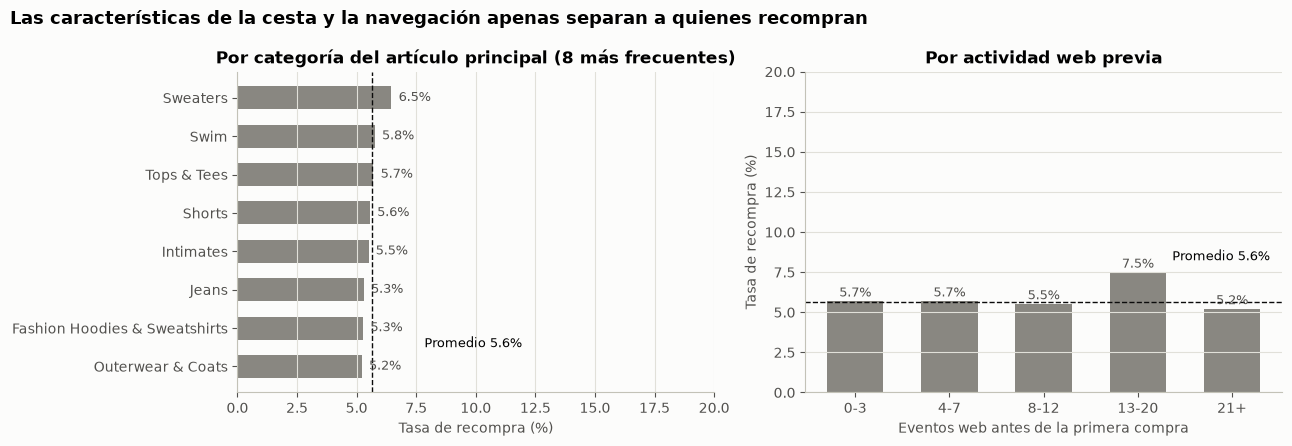

,clientes,tasa
category_highest_price_item,,
Outerwear & Coats,3583,5.22
Fashion Hoodies & Sweatshirts,3827,5.28
Jeans,4750,5.31
Intimates,3945,5.50
Shorts,3542,5.56
Tops & Tees,3539,5.71
Swim,3765,5.76
Sweaters,3899,6.46


,clientes,tasa
grupo_eventos,,
0-3,704,5.68
4-7,36667,5.69
8-12,12904,5.51
13-20,1551,7.48
21+,6341,5.20


In [4]:
TASA_GLOBAL = df_lab[OBJETIVO].mean() * 100
ESCALA_TASA = (0, 20)  # misma escala en todos los graficos de tasas para compararlos


def tasa_por_grupo(datos, columna):
    """Clientes y tasa de recompra (%) por grupo."""
    return (
        datos.groupby(columna, observed=True)[OBJETIVO]
        .agg(clientes="size", tasa="mean")
        .assign(tasa=lambda t: t["tasa"] * 100)
    )


def rotular_barras(ax, barras, valores, horizontal=False):
    for barra, valor in zip(barras, valores):
        if horizontal:
            ax.text(barra.get_width() + 0.3, barra.get_y() + barra.get_height() / 2,
                    f"{valor:.1f}%", va="center", fontsize=9, color=COLORES["tinta_2"])
        else:
            ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.3,
                    f"{valor:.1f}%", ha="center", fontsize=9, color=COLORES["tinta_2"])


categorias = (
    tasa_por_grupo(df_lab, "category_highest_price_item")
    .nlargest(8, "clientes")
    .sort_values("tasa")
)
grupo_eventos = pd.cut(
    df_lab["n_events_pre"], bins=[-1, 3, 7, 12, 20, np.inf],
    labels=["0-3", "4-7", "8-12", "13-20", "21+"],
)
eventos = tasa_por_grupo(df_lab.assign(grupo_eventos=grupo_eventos), "grupo_eventos")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

barras = axes[0].barh(categorias.index, categorias["tasa"], color=COLORES["contexto"], height=0.6)
rotular_barras(axes[0], barras, categorias["tasa"], horizontal=True)
axes[0].axvline(TASA_GLOBAL, color=COLORES["tinta"], linestyle="--", linewidth=1)
axes[0].text(TASA_GLOBAL + 2.2, 0.5, f"Promedio {TASA_GLOBAL:.1f}%", fontsize=9)
axes[0].set_xlim(*ESCALA_TASA)
axes[0].set_xlabel("Tasa de recompra (%)")
axes[0].set_title("Por categoría del artículo principal (8 más frecuentes)")
axes[0].grid(axis="y", visible=False)

barras = axes[1].bar(eventos.index.astype(str), eventos["tasa"], color=COLORES["contexto"], width=0.6)
rotular_barras(axes[1], barras, eventos["tasa"])
axes[1].axhline(TASA_GLOBAL, color=COLORES["tinta"], linestyle="--", linewidth=1)
axes[1].text(4.4, TASA_GLOBAL + 2.6, f"Promedio {TASA_GLOBAL:.1f}%", ha="right", fontsize=9)
axes[1].set_ylim(*ESCALA_TASA)
axes[1].set_xlabel("Eventos web antes de la primera compra")
axes[1].set_ylabel("Tasa de recompra (%)")
axes[1].set_title("Por actividad web previa")
axes[1].grid(axis="x", visible=False)

fig.suptitle("Las características de la cesta y la navegación apenas separan a quienes recompran",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

display(categorias.round(2))
display(eventos.round(2))

Las tasas se muestran en la misma escala (0–20%) que la sección 6.2 para que la comparación sea visual:

- **Categoría:** entre las ocho categorías más frecuentes, la tasa solo varía entre 5,2% (`Outerwear & Coats`) y 6,5% (`Sweaters`), alrededor del promedio de 5,6%.
- **Actividad web previa:** la relación es plana (5,2%–5,7%). La única excepción es el grupo de 13–20 eventos (7,5%), que reúne solo 1.551 clientes y no sigue una tendencia.

Estas variables aportan poca información por sí solas. Se mantienen como candidatas, y el modelo decide en la sección 8.3 si aportan algo en combinación.

#### 6.2. Señal fuerte: antigüedad del cliente y cohorte de registro

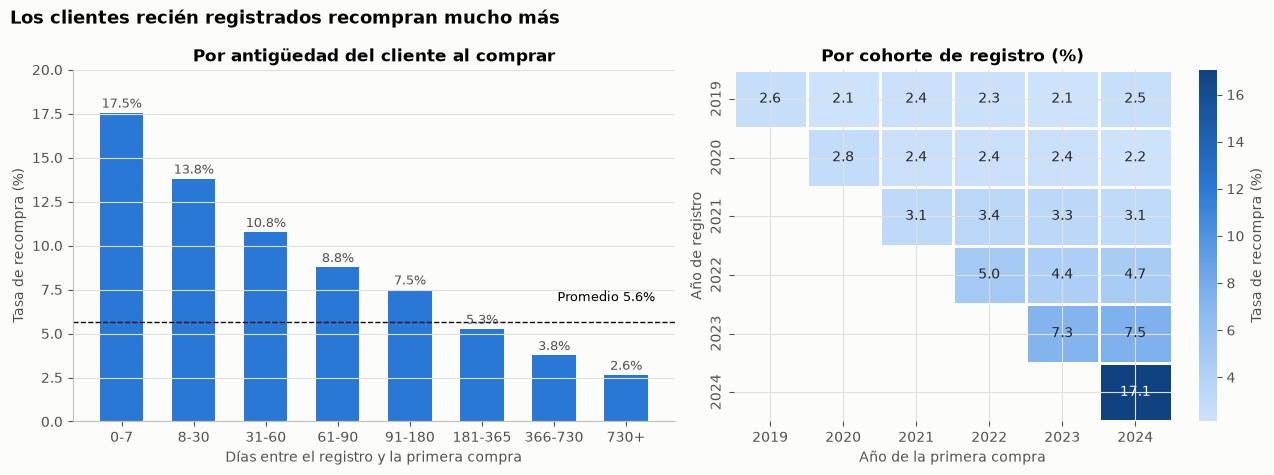

,clientes,tasa
tramo,,
0-7,1026,17.54
8-30,2893,13.79
31-60,3403,10.76
61-90,2967,8.76
91-180,7587,7.49
181-365,11174,5.25
366-730,13731,3.76
730+,15386,2.64


In [5]:
tramos = pd.cut(
    df_lab["days_since_signup"],
    bins=[-1, 7, 30, 60, 90, 180, 365, 730, np.inf],
    labels=["0-7", "8-30", "31-60", "61-90", "91-180", "181-365", "366-730", "730+"],
)
por_tramo = tasa_por_grupo(df_lab.assign(tramo=tramos), "tramo")

# Cohorte: anio de registro (fecha de primera compra - antiguedad)
cohortes = df_lab.assign(
    anio_registro=(
        df_lab["first_order_ts"] - pd.to_timedelta(df_lab["days_since_signup"], unit="D")
    ).dt.year,
    anio_compra=df_lab["first_order_ts"].dt.year,
)
tasa_cohorte = cohortes.pivot_table(
    index="anio_registro", columns="anio_compra", values=OBJETIVO, aggfunc="mean"
) * 100
n_cohorte = cohortes.pivot_table(
    index="anio_registro", columns="anio_compra", values=OBJETIVO, aggfunc="size"
)
tasa_cohorte = tasa_cohorte.where(n_cohorte >= 100)  # se ocultan celdas con menos de 100 clientes

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})

barras = axes[0].bar(por_tramo.index.astype(str), por_tramo["tasa"], color=COLORES["modelo"], width=0.6)
rotular_barras(axes[0], barras, por_tramo["tasa"])
axes[0].axhline(TASA_GLOBAL, color=COLORES["tinta"], linestyle="--", linewidth=1)
axes[0].text(7.4, TASA_GLOBAL + 1.2, f"Promedio {TASA_GLOBAL:.1f}%", ha="right", fontsize=9)
axes[0].set_ylim(*ESCALA_TASA)
axes[0].set_xlabel("Días entre el registro y la primera compra")
axes[0].set_ylabel("Tasa de recompra (%)")
axes[0].set_title("Por antigüedad del cliente al comprar")
axes[0].grid(axis="x", visible=False)

sns.heatmap(
    tasa_cohorte, ax=axes[1], cmap=AZULES, annot=True, fmt=".1f",
    linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Tasa de recompra (%)"},
)
axes[1].set_xlabel("Año de la primera compra")
axes[1].set_ylabel("Año de registro")
axes[1].set_title("Por cohorte de registro (%)")

fig.suptitle("Los clientes recién registrados recompran mucho más",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

display(por_tramo.round(2))

Este es el **hallazgo principal del análisis exploratorio**.

**1. La antigüedad del cliente al comprar es la variable más discriminante.** Quien hace su primera compra en la primera semana tras registrarse recompra en un 17,5% de los casos. Quien tarda más de dos años, solo en un 2,6%: una diferencia de 6,6 veces. La relación es claramente no lineal, con una caída rápida en los primeros 90 días que luego se suaviza.

**2. El aumento de la recompra en el tiempo es un efecto de cohorte.** La tasa de recompra crece entre 2019 y 2024 (de ~3,6% en los clientes más antiguos a 12,3% en el periodo de prueba). El mapa de calor muestra que ese crecimiento **no depende del año de la primera compra, sino del año de registro**:

- Dentro de cada cohorte (cada fila), la tasa es prácticamente constante en el tiempo. Por ejemplo, la cohorte 2019 se mantiene en 2,1%–2,6%.
- Entre cohortes, la tasa sube de forma sostenida: ~2,5% (2019–2020), ~3,2% (2021), ~4,7% (2022), ~7,4% (2023) y 17,1% (2024).

Como en los periodos recientes predominan clientes de cohortes recientes, la tasa global sube. Con los datos disponibles no es posible determinar la causa. Puede tratarse de un artefacto de la generación del dataset ficticio o, en un negocio real, de cambios en la captación o el onboarding. En cualquier caso, debe vigilarse en producción.

**Implicaciones para el modelo:**

- `days_since_signup` debe entrar con una forma no lineal: *spline* sobre su logaritmo.
- Una regla simple basada solo en esta variable es una **referencia exigente**, que el modelo tiene que superar.
- El entrenamiento debe dar más peso a los clientes recientes, y la evaluación tiene que ser temporal.
- Con una tasa en aumento, las probabilidades estimadas con datos pasados tenderán a quedarse cortas.

#### 6.3. Tiempo hasta la recompra

Se analizan los días entre la primera y la segunda orden válida de los clientes que recompraron dentro de la ventana (`SQL/15_tiempo_entre_compras.sql`). Este dato es posterior a la primera compra, así que **solo se usa de forma descriptiva** y nunca como variable predictora.

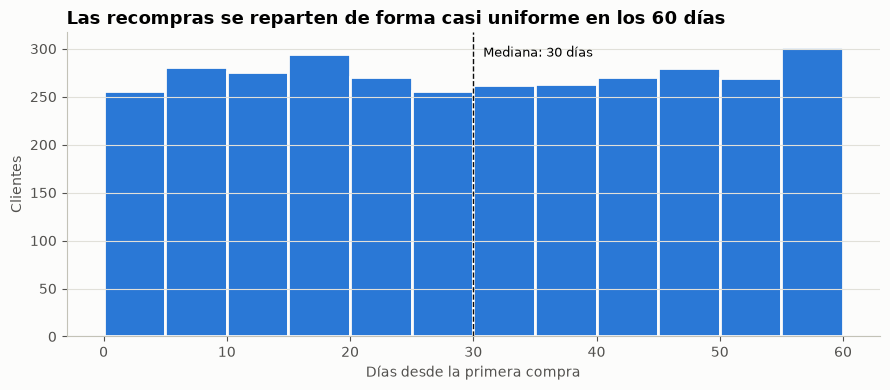

Clientes con recompra: 3,282
Media: 29.8 días | Mediana: 30 días
Recompras en los primeros 15 días: 26.7%


In [6]:
df_tiempo = cargar_tiempo_recompra(CONFIG)

# Consistencia con la etiqueta del modelo
positivos = set(df_lab.loc[df_lab[OBJETIVO] == 1, "user_id"])
sin_tiempo = positivos - set(df_tiempo["user_id"])
assert not sin_tiempo, f"{len(sin_tiempo)} recompradores sin tiempo de recompra"
df_tiempo = df_tiempo.loc[df_tiempo["user_id"].isin(positivos)]
assert df_tiempo["user_id"].is_unique
assert df_tiempo["dias_hasta_recompra"].between(0, CONFIG["ventana_dias"]).all()

dias = df_tiempo["dias_hasta_recompra"]
primeros_15 = (dias <= 15).mean()

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(dias, bins=np.arange(0, 65, 5), color=COLORES["modelo"], edgecolor="#fcfcfb", linewidth=2)
ax.axvline(dias.median(), color=COLORES["tinta"], linestyle="--", linewidth=1)
ax.text(dias.median() + 0.8, ax.get_ylim()[1] * 0.92, f"Mediana: {dias.median():.0f} días", fontsize=9)
ax.set_xlabel("Días desde la primera compra")
ax.set_ylabel("Clientes")
ax.set_title("Las recompras se reparten de forma casi uniforme en los 60 días",
             loc="left", fontsize=13)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Clientes con recompra: {len(dias):,}")
print(f"Media: {dias.mean():.1f} días | Mediana: {dias.median():.0f} días")
print(f"Recompras en los primeros 15 días: {primeros_15:.1%}")

Las 3.282 recompras se distribuyen de forma casi uniforme a lo largo de la ventana (media 29,8 días, mediana 30). El 26,7% ocurre en los primeros 15 días.

**Implicación para el negocio:** no hay un "momento natural" de recompra que se pueda esperar.

- Una cuarta parte de las recompras ocurre en las dos primeras semanas. Por eso el contacto debe activarse **justo después de la primera compra**, y la puntuación está disponible en ese momento.
- Como las recompras siguen llegando a un ritmo constante, tiene sentido un segundo contacto hacia la mitad de la ventana. La salida del pipeline incluye `dias_restantes_ventana` para programarlo.

**Limitación:** el análisis solo incluye a quienes recompraron dentro de los 60 días. No describe el tiempo de recompra de toda la población.

#### 6.4. Síntesis del análisis exploratorio

| Pregunta | Respuesta | Decisión que orienta |
|---|---|---|
| ¿Qué separa a quienes recompran? | Sobre todo, el poco tiempo entre el registro y la primera compra. La cesta, la categoría y la navegación aportan poco | Tratar `days_since_signup` de forma no lineal y usarla como referencia exigente; seleccionar variables |
| ¿Es estable la tasa? | No: pasa de ~3,6% a 12,3%, por un efecto de cohorte de registro | Evaluación temporal, ponderación por recencia y vigilancia de la calibración |
| ¿Cuándo se recompra? | De forma uniforme en los 60 días; 27% en los primeros 15 | Puntuar y contactar justo después de la primera compra |
| ¿Cuánto desbalance hay? | 5,6% de positivos | Métricas sobre la clase positiva (AP, Precision, Recall, F1) y decisión por ranking |

### 7. Diseño de la evaluación temporal

#### 7.1. Por qué un backtest y no una única validación

Una división clásica en entrenamiento, validación y prueba (70/15/15) deja un único bloque de validación (abril–junio 2024) con solo ~360 recompradores. Con tan pocos positivos, el *Average Precision* (AP) varía ±0,01–0,02 entre muestras parecidas. Esa diferencia es mayor que la que separa a los modelos comparados, así que decidir el modelo con un único bloque sería poco fiable.

Por eso se mantiene el último 15% como prueba final y se sustituye la validación única por un **backtest con ventana expansiva**:

| Elemento | Definición |
|---|---|
| **Prueba (holdout final)** | El último 15% de clientes por fecha de primera compra. Solo se usa una vez, al final |
| **Desarrollo** | Clientes cuya etiqueta ya estaba completa al inicio de prueba (hueco de 60 días) |
| **Backtest** | Bloques trimestrales de validación desde 2023. Cada bloque se valida con un modelo entrenado solo con clientes cuya etiqueta estaba completa al inicio del bloque |

Este esquema imita lo que haría el proceso en producción: reentrenar periódicamente con la historia disponible y predecir el trimestre siguiente.

**Métrica de selección:** *lift de AP* = AP / tasa de recompra del bloque. La tasa de recompra cambia de un trimestre a otro (sección 6.2), por lo que el AP en bruto no es comparable entre bloques. Un lift de AP igual a 1 equivale a ordenar al azar.

In [7]:
def particion_temporal(df_lab, cfg):
    """Separa desarrollo y prueba por fecha de primera compra, con hueco de 60 dias."""
    ventana = pd.Timedelta(days=cfg["ventana_dias"])
    ordenado = df_lab.sort_values(["first_order_ts", "user_id"]).reset_index(drop=True)
    inicio_test = ordenado.loc[int(len(ordenado) * (1 - cfg["frac_test"])), "first_order_ts"]
    test = ordenado.loc[ordenado["first_order_ts"] >= inicio_test].copy()
    dev = ordenado.loc[ordenado["first_order_ts"] + ventana <= inicio_test].copy()
    return dev, test, inicio_test


def folds_backtest(dev, inicio_test, cfg):
    """Bloques de validacion con entrenamiento expansivo y hueco de 60 dias."""
    ventana = pd.Timedelta(days=cfg["ventana_dias"])
    limite = inicio_test - ventana
    inicios = pd.date_range(
        pd.Timestamp(cfg["inicio_backtest"], tz="UTC"), limite,
        freq=f"{cfg['meses_por_fold']}MS",
    )
    folds = []
    for inicio in inicios:
        fin = min(inicio + pd.DateOffset(months=cfg["meses_por_fold"]), limite)
        train = dev.loc[dev["first_order_ts"] + ventana <= inicio]
        val = dev.loc[(dev["first_order_ts"] >= inicio) & (dev["first_order_ts"] < fin)]
        if len(val) > 0 and val[OBJETIVO].nunique() == 2:
            folds.append({"inicio": inicio, "fin": fin, "train": train, "val": val})
    return folds


df_dev, df_test, INICIO_TEST = particion_temporal(df_lab, CONFIG)
FOLDS = folds_backtest(df_dev, INICIO_TEST, CONFIG)

# Verificaciones: sin solapamiento y con el hueco temporal respetado
ventana = pd.Timedelta(days=CONFIG["ventana_dias"])
assert df_dev["first_order_ts"].max() + ventana <= df_test["first_order_ts"].min()
assert not set(df_dev["user_id"]) & set(df_test["user_id"])
for f in FOLDS:
    assert f["train"]["first_order_ts"].max() + ventana <= f["val"]["first_order_ts"].min()

filas = [{
    "Conjunto": f"Backtest {i}",
    "Validacion desde": f["inicio"].date(),
    "Validacion hasta": f["fin"].date(),
    "Clientes entrenamiento": len(f["train"]),
    "Clientes validacion": len(f["val"]),
    "Recompradores validacion": int(f["val"][OBJETIVO].sum()),
    "Tasa validacion (%)": round(f["val"][OBJETIVO].mean() * 100, 2),
} for i, f in enumerate(FOLDS, start=1)]
filas.append({
    "Conjunto": "Prueba final",
    "Validacion desde": df_test["first_order_ts"].min().date(),
    "Validacion hasta": df_test["first_order_ts"].max().date(),
    "Clientes entrenamiento": len(df_dev),
    "Clientes validacion": len(df_test),
    "Recompradores validacion": int(df_test[OBJETIVO].sum()),
    "Tasa validacion (%)": round(df_test[OBJETIVO].mean() * 100, 2),
})
display(pd.DataFrame(filas))
print("Clientes excluidos por el hueco de 60 dias:", len(df_lab) - len(df_dev) - len(df_test))

,Conjunto,Validacion desde,Validacion hasta,Clientes entrenamiento,Clientes validacion,Recompradores validacion,Tasa validacion (%)
0,Backtest 1,2023-01-01,2023-04-01,19769,3105,108,3.48
1,Backtest 2,2023-04-01,2023-07-01,22718,3310,141,4.26
2,Backtest 3,2023-07-01,2023-10-01,25903,3877,166,4.28
3,Backtest 4,2023-10-01,2024-01-01,29368,4100,216,5.27
4,Backtest 5,2024-01-01,2024-04-01,33338,4667,262,5.61
5,Backtest 6,2024-04-01,2024-06-25,37618,4907,357,7.28
6,Prueba final,2024-08-24,2024-12-16,45650,8726,1075,12.32


Clientes excluidos por el hueco de 60 dias: 3791


Se generan seis bloques trimestrales de validación entre enero de 2023 y junio de 2024. Cada uno tiene entre 108 y 357 recompradores y su propio conjunto de entrenamiento expansivo (de 19.769 a 37.618 clientes). El último bloque se corta el 25/06/2024 para respetar el hueco de 60 días con la prueba.

La prueba final (24/08/2024 – 16/12/2024) tiene 8.726 clientes y 1.075 recompradores, con una tasa del 12,3%. El modelo final de evaluación se entrena con los 45.650 clientes de desarrollo. El hueco de 60 días deja fuera 3.791 clientes cuya etiqueta todavía no estaría disponible al inicio de la prueba.

Las verificaciones confirman que no hay clientes compartidos entre desarrollo y prueba y que, en cada bloque, el entrenamiento termina al menos 60 días antes del inicio de la validación.

### 8. Modelado

#### 8.1. Referencias, candidatos y preprocesamiento

**Referencias sencillas** (el modelo tiene que superarlas para aportar valor):

| Referencia | Descripción |
|---|---|
| **Aleatoria** | Ordena a los clientes al azar. Equivale a `DummyClassifier` (AP = tasa de recompra) y es la referencia mínima |
| **Regla "registro reciente"** | Prioriza a quien compró poco después de registrarse (menor `days_since_signup`). Es una regla de negocio sin entrenamiento y la referencia exigente, porque el EDA mostró que esa variable concentra la señal |

**Candidatos de clasificación:**

| Candidato | Descripción |
|---|---|
| **LR completa** | Regresión logística con las 18 variables. `days_since_signup` entra como *spline* sobre su logaritmo, para captar la caída no lineal; las variables asimétricas, en logaritmo; las categorías poco frecuentes se agrupan. Sin `class_weight` y ponderada por recencia |
| **HGB** | `HistGradientBoostingClassifier` poco profundo y regularizado, ponderado por recencia. Representa a los modelos de árboles de *gradient boosting*, capaces de captar no linealidades e interacciones sin especificarlas |
| **LR parsimoniosa** | Igual que la LR completa, pero solo con las variables que aportan de forma consistente en el backtest (sección 8.3) |

**Decisiones de modelado:**

1. **Sin `class_weight="balanced"`.** Reequilibrar las clases apenas cambia el orden de los clientes, pero desplaza todas las puntuaciones hacia 0,5: con un 5,6% de positivos, el modelo pasaría a predecir de media en torno al 50%. Sin reequilibrado, las puntuaciones se pueden interpretar como probabilidades, que es lo que pide el negocio. El desbalance se trata en la evaluación (AP y métricas sobre la clase positiva) y en la decisión comercial (ranking), no alterando el entrenamiento.
2. **Ponderación por recencia.** Cada cliente de entrenamiento pesa `0,5 ^ (antigüedad / 365 días)`, para que el modelo se adapte al cambio de comportamiento entre cohortes sin descartar la historia.

In [8]:
ASIMETRICAS = ["order_value", "n_events_pre", "n_product_views_pre", "n_cart_events_pre"]


def _log1p():
    return FunctionTransformer(np.log1p, feature_names_out="one-to-one")


def construir_preprocesador(numericas, categoricas):
    """Preprocesamiento de la regresion logistica."""
    pasos = []
    if "days_since_signup" in numericas:
        pasos.append(("registro", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("log", _log1p()),
            ("spline", SplineTransformer(n_knots=5, degree=3)),
        ]), ["days_since_signup"]))
    asimetricas = [c for c in numericas if c in ASIMETRICAS]
    if asimetricas:
        pasos.append(("asimetricas", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("log", _log1p()),
            ("escalar", StandardScaler()),
        ]), asimetricas))
    lineales = [c for c in numericas if c not in ASIMETRICAS and c != "days_since_signup"]
    if lineales:
        pasos.append(("lineales", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]), lineales))
    if categoricas:
        pasos.append(("categoricas", Pipeline([
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), categoricas))
    return ColumnTransformer(pasos)


class ReglaRegistroReciente(ClassifierMixin, BaseEstimator):
    """Referencia: prioriza a quien compro poco despues de registrarse.

    No aprende nada; la puntuacion solo sirve para ordenar clientes.
    """

    def fit(self, X, y, sample_weight=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        puntuacion = 1 / (1 + np.log1p(X["days_since_signup"].to_numpy(dtype=float)))
        return np.column_stack([1 - puntuacion, puntuacion])


class ReferenciaAleatoria(ClassifierMixin, BaseEstimator):
    """Referencia: orden aleatorio de los clientes (AP esperado = prevalencia)."""

    def __init__(self, semilla=42):
        self.semilla = semilla

    def fit(self, X, y, sample_weight=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        puntuacion = np.random.default_rng(self.semilla).random(len(X))
        return np.column_stack([1 - puntuacion, puntuacion])


def especificacion(nombre, modelo, variables, pesos, probabilistico=True):
    return {"nombre": nombre, "modelo": modelo, "variables": list(variables),
            "pesos": pesos, "probabilistico": probabilistico}


def spec_lr(nombre, numericas, categoricas):
    modelo = Pipeline([
        ("preprocesador", construir_preprocesador(numericas, categoricas)),
        ("clasificador", LogisticRegression(max_iter=3000)),
    ])
    return especificacion(nombre, modelo, numericas + categoricas, pesos=True)


def spec_hgb(cfg):
    preprocesador = ColumnTransformer([
        ("num", "passthrough", NUMERICAS),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAS),
    ])
    clasificador = HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=200,
        l2_regularization=1.0, random_state=cfg["semilla"],
        categorical_features=list(range(len(NUMERICAS), len(NUMERICAS) + len(CATEGORICAS))),
    )
    modelo = Pipeline([("preprocesador", preprocesador), ("clasificador", clasificador)])
    return especificacion("HGB", modelo, NUMERICAS + CATEGORICAS, pesos=True)


REGLA = especificacion("Regla registro reciente", ReglaRegistroReciente(),
                       ["days_since_signup"], pesos=False, probabilistico=False)
ALEATORIA = especificacion("Aleatoria", ReferenciaAleatoria(CONFIG["semilla"]),
                           ["days_since_signup"], pesos=False, probabilistico=False)


def pesos_recencia(fechas, fecha_referencia, cfg):
    """Peso 1 para los clientes mas recientes; se reduce a la mitad cada vida_media_dias."""
    antiguedad = (fecha_referencia - fechas).dt.days.clip(lower=0).to_numpy()
    return 0.5 ** (antiguedad / cfg["vida_media_dias"])


def ajustar(spec, datos, fecha_referencia, cfg):
    """Entrena una copia limpia del modelo de la especificacion."""
    modelo = clone(spec["modelo"])
    X, y = datos[spec["variables"]], datos[OBJETIVO].astype(int)
    if spec["pesos"]:
        modelo.fit(X, y, clasificador__sample_weight=pesos_recencia(
            datos["first_order_ts"], fecha_referencia, cfg))
    else:
        modelo.fit(X, y)
    return modelo


def puntuar(modelo, spec, datos):
    return modelo.predict_proba(datos[spec["variables"]])[:, 1]


def metricas(y_real, puntuacion, cfg, probabilistico=True):
    """Metricas de ranking y de la decision comercial (contactar al top pct_contacto)."""
    y = np.asarray(y_real).astype(int)
    s = np.asarray(puntuacion, dtype=float)
    prevalencia = y.mean()
    orden = np.argsort(-s, kind="stable")

    def seleccion(pct):
        elegidos = np.zeros(len(y), dtype=int)
        elegidos[orden[:int(np.ceil(len(y) * pct))]] = 1
        return elegidos

    top10, contacto = seleccion(0.10), seleccion(cfg["pct_contacto"])
    ap = average_precision_score(y, s)
    return {
        "AP": ap,
        "Lift AP": ap / prevalencia,
        "ROC AUC": roc_auc_score(y, s),
        "Lift@10%": precision_score(y, top10) / prevalencia,
        "Precision@contacto": precision_score(y, contacto),
        "Recall@contacto": recall_score(y, contacto),
        "F1@contacto": f1_score(y, contacto),
        "Brier": brier_score_loss(y, s) if probabilistico else np.nan,
        "Media predicha": s.mean() if probabilistico else np.nan,
        "Tasa real": prevalencia,
    }


def evaluar_backtest(specs, folds, cfg):
    filas = []
    for spec in specs:
        for i, f in enumerate(folds, start=1):
            modelo = ajustar(spec, f["train"], f["inicio"], cfg)
            p = puntuar(modelo, spec, f["val"])
            ap = average_precision_score(f["val"][OBJETIVO], p)
            filas.append({"Modelo": spec["nombre"], "Fold": i,
                          "Trimestre": f"{f['inicio'].year}-T{(f['inicio'].month - 1) // 3 + 1}",
                          "AP": ap, "Lift AP": ap / f["val"][OBJETIVO].mean()})
    return pd.DataFrame(filas)

#### 8.2. Backtest de referencias y candidatos

In [9]:
SPEC_LR_COMPLETA = spec_lr("LR completa", NUMERICAS, CATEGORICAS)
SPEC_HGB = spec_hgb(CONFIG)

backtest = evaluar_backtest([ALEATORIA, REGLA, SPEC_LR_COMPLETA, SPEC_HGB], FOLDS, CONFIG)

tabla_backtest = backtest.pivot_table(index="Modelo", columns="Trimestre", values="Lift AP")
tabla_backtest["Media"] = tabla_backtest.mean(axis=1)
tabla_backtest["Desv."] = backtest.groupby("Modelo")["Lift AP"].std()
display(tabla_backtest.sort_values("Media", ascending=False).round(3))

Trimestre,2023-T1,2023-T2,2023-T3,2023-T4,2024-T1,2024-T2,Media,Desv.
Modelo,,,,,,,,
Regla registro reciente,1.636,1.321,1.815,1.711,1.578,1.670,1.622,0.167
LR completa,1.155,1.231,1.484,1.776,1.469,1.532,1.441,0.223
HGB,1.073,1.109,1.544,1.667,1.476,1.551,1.403,0.250
Aleatoria,1.236,1.098,1.031,0.916,1.042,1.050,1.062,0.104


Lift de AP por trimestre (1 = orden aleatorio):

- **La regla "registro reciente" es la mejor referencia en promedio (1,62).** Ninguno de los modelos con todas las variables la supera.
- **La LR completa alcanza 1,44.** Supera claramente al orden aleatorio, pero queda por debajo de la regla en 5 de los 6 trimestres.
- **HGB (1,40) no mejora a la regresión logística.** No hay evidencia de interacciones complejas que justifiquen un modelo de árboles, así que se prioriza la regresión logística por simplicidad e interpretabilidad.
- **La referencia aleatoria queda en ~1,06**, como se espera. Su variación (0,92–1,24) da una idea del ruido de cada bloque.

Que una sola variable le gane a 18 indica que las variables restantes añaden más ruido que señal. Esto motiva la selección de variables de la sección 8.3.

#### 8.3. Selección de variables por importancia en el backtest

Para comprobar qué variables aportan realmente, se calcula la **importancia por permutación** de la LR completa en cada bloque del backtest. La importancia mide cuánto cae el AP de validación al desordenar una variable, y se expresa en unidades de lift de AP para que los bloques sean comparables.

Una variable se conserva si su importancia media es positiva **y** es positiva en al menos la mitad de los bloques. Es decir, si aporta de forma consistente y no solo en un trimestre.

In [10]:
def importancia_backtest(spec, folds, cfg, repeticiones=5):
    importancias = []
    for f in folds:
        modelo = ajustar(spec, f["train"], f["inicio"], cfg)
        resultado = permutation_importance(
            modelo, f["val"][spec["variables"]], f["val"][OBJETIVO],
            scoring="average_precision", n_repeats=repeticiones,
            random_state=cfg["semilla"],
        )
        importancias.append(pd.Series(
            resultado.importances_mean / f["val"][OBJETIVO].mean(), index=spec["variables"]))
    tabla = pd.concat(importancias, axis=1)
    return pd.DataFrame({
        "Importancia media": tabla.mean(axis=1),
        "Bloques con aporte positivo": (tabla > 0).sum(axis=1),
    }).sort_values("Importancia media", ascending=False)


importancia = importancia_backtest(SPEC_LR_COMPLETA, FOLDS, CONFIG)
importancia["Seleccionada"] = (
    (importancia["Importancia media"] > 0)
    & (importancia["Bloques con aporte positivo"] >= len(FOLDS) / 2)
)
display(importancia.round(4))

VARS_SELECCIONADAS = importancia.index[importancia["Seleccionada"]].tolist()
SPEC_LR_PARSIMONIOSA = spec_lr(
    "LR parsimoniosa",
    [c for c in NUMERICAS if c in VARS_SELECCIONADAS],
    [c for c in CATEGORICAS if c in VARS_SELECCIONADAS],
)
print("Variables de la LR parsimoniosa:", SPEC_LR_PARSIMONIOSA["variables"])

,Importancia media,Bloques con aporte positivo,Seleccionada
days_since_signup,0.3815,6,True
n_product_views_pre,0.1118,5,True
n_sessions_pre,0.1047,5,True
n_cart_events_pre,0.0902,5,True
n_items,0.0541,5,True
n_distinct_products,0.0497,5,True
first_order_month,0.0359,4,True
n_brands,0.0344,4,True
n_events_pre,0.0274,3,True
first_order_dow,0.0104,4,True


Variables de la LR parsimoniosa: ['n_items', 'n_distinct_products', 'n_categories', 'n_brands', 'days_since_signup', 'n_events_pre', 'n_sessions_pre', 'n_product_views_pre', 'n_cart_events_pre', 'gender', 'traffic_source', 'department_highest_price_item', 'first_order_month', 'first_order_dow']


`days_since_signup` domina con claridad: su importancia (0,38) es más del triple que la de la siguiente variable. Después aparecen las métricas de navegación previa y el tamaño de la cesta, con aportes pequeños pero consistentes.

Se descartan `country`, `age`, `order_value` y `category_highest_price_item`, que empeoran el AP en la mayoría de los bloques. Esto coincide con el análisis exploratorio. La LR parsimoniosa queda con 14 variables.

**Precaución:** las variables se seleccionaron con los mismos bloques que se usan para comparar modelos, por lo que el backtest de la LR parsimoniosa es algo optimista. La comprobación sin sesgo es la prueba final (sección 9), que no interviene en ninguna decisión.

#### 8.4. Comparación final del backtest y selección del modelo

El criterio de selección se fija antes de ver la prueba: **entre los candidatos de clasificación, se elige el de mayor lift de AP medio en el backtest**. Después se compara con la regla de referencia en la prueba final.

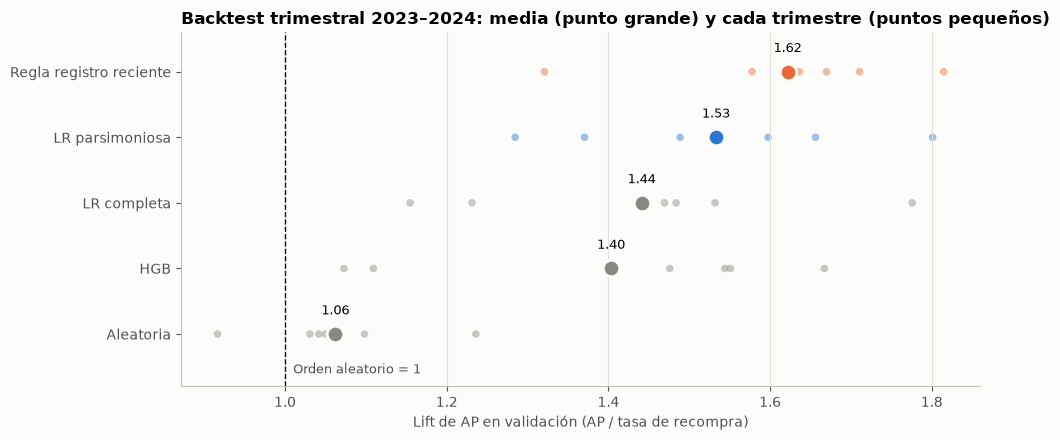

Trimestre,2023-T1,2023-T2,2023-T3,2023-T4,2024-T1,2024-T2,Media,Desv.
Modelo,,,,,,,,
Regla registro reciente,1.636,1.321,1.815,1.711,1.578,1.670,1.622,0.167
LR parsimoniosa,1.370,1.285,1.489,1.801,1.656,1.597,1.533,0.190
LR completa,1.155,1.231,1.484,1.776,1.469,1.532,1.441,0.223
HGB,1.073,1.109,1.544,1.667,1.476,1.551,1.403,0.250
Aleatoria,1.236,1.098,1.031,0.916,1.042,1.050,1.062,0.104


Modelo seleccionado: LR parsimoniosa


In [11]:
backtest = pd.concat([
    backtest,
    evaluar_backtest([SPEC_LR_PARSIMONIOSA], FOLDS, CONFIG),
], ignore_index=True)

resumen_bt = (
    backtest.groupby("Modelo")["Lift AP"]
    .agg(["mean", "std", "min", "max"])
    .sort_values("mean")
)

CANDIDATOS = {s["nombre"]: s for s in [SPEC_LR_COMPLETA, SPEC_HGB, SPEC_LR_PARSIMONIOSA]}
NOMBRE_SELECCIONADO = resumen_bt.loc[list(CANDIDATOS)]["mean"].idxmax()
SPEC_FINAL = CANDIDATOS[NOMBRE_SELECCIONADO]

# Grafico: lift de AP por bloque (puntos) y media (marcador grande)
color_modelo = {nombre: COLORES["contexto"] for nombre in resumen_bt.index}
color_modelo[NOMBRE_SELECCIONADO] = COLORES["modelo"]
color_modelo[REGLA["nombre"]] = COLORES["regla"]

fig, ax = plt.subplots(figsize=(10, 4.5))
for posicion, nombre in enumerate(resumen_bt.index):
    valores = backtest.loc[backtest["Modelo"] == nombre, "Lift AP"]
    ax.scatter(valores, np.full(len(valores), posicion), s=30, alpha=0.45,
               color=color_modelo[nombre], edgecolor="none")
    ax.scatter(resumen_bt.loc[nombre, "mean"], posicion, s=140, color=color_modelo[nombre],
               edgecolor="#fcfcfb", linewidth=2, zorder=3)
    ax.text(resumen_bt.loc[nombre, "mean"], posicion + 0.3,
            f"{resumen_bt.loc[nombre, 'mean']:.2f}", ha="center", fontsize=9)
ax.axvline(1, color=COLORES["tinta"], linestyle="--", linewidth=1)
ax.text(1.01, -0.6, "Orden aleatorio = 1", fontsize=9, color=COLORES["tinta_2"])
ax.set_yticks(range(len(resumen_bt)), resumen_bt.index)
ax.set_ylim(-0.8, len(resumen_bt) - 0.4)
ax.set_xlabel("Lift de AP en validación (AP / tasa de recompra)")
ax.set_title("Backtest trimestral 2023–2024: media (punto grande) y cada trimestre (puntos pequeños)",
             loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

tabla_backtest = backtest.pivot_table(index="Modelo", columns="Trimestre", values="Lift AP")
tabla_backtest["Media"] = resumen_bt["mean"]
tabla_backtest["Desv."] = resumen_bt["std"]
display(tabla_backtest.sort_values("Media", ascending=False).round(3))
print("Modelo seleccionado:", NOMBRE_SELECCIONADO)

**Modelo seleccionado: LR parsimoniosa** (lift de AP medio de 1,53, frente a 1,44 de la LR completa y 1,40 de HGB).

La regla de referencia sigue por delante en promedio (1,62). Sin embargo, la dispersión entre trimestres (desviación ~0,17–0,19) es mayor que la diferencia entre ambos, y el modelo la supera en dos de los seis trimestres (2023-T4 y 2024-T1). Ninguno de los dos domina con claridad.

El modelo se mantiene como solución principal por tres razones:

1. Produce **probabilidades** y no solo un orden.
2. Permite incorporar nuevas variables sin rediseñar el proceso.
3. Su ventaja frente a la regla varía según el periodo (ver la sección 10.3).

La regla se conserva como **referencia permanente** para monitorear que el modelo siga aportando valor.

### 9. Evaluación final en el periodo de prueba

Todos los modelos se reentrenan con el conjunto de desarrollo completo y se evalúan **una sola vez** sobre el periodo de prueba (agosto–diciembre 2024). En prueba no se ajusta nada.

**Punto de operación.** En lugar de un umbral de probabilidad elegido maximizando F1, la decisión se define por **capacidad comercial**: se contacta al `pct_contacto` = 30% de clientes con mayor puntuación. Hay dos motivos:

1. Con una señal débil, el umbral que maximiza F1 suele marcar como positivos a la mayoría de los clientes, lo que no es una campaña viable.
2. Con una tasa de recompra cambiante (7% en validación, 12% en prueba), un umbral fijo de probabilidad se desplaza. Un corte por percentil, en cambio, siempre selecciona el volumen que el negocio puede atender.

Precision, Recall y F1 se reportan en ese punto de operación. El AP resume la calidad del orden en todos los umbrales.

#### 9.1. Resultados por modelo

In [12]:
modelos_test, puntuaciones_test = {}, {}
SPECS = {s["nombre"]: s for s in [ALEATORIA, REGLA, SPEC_LR_COMPLETA, SPEC_HGB, SPEC_LR_PARSIMONIOSA]}
for nombre, spec in SPECS.items():
    modelos_test[nombre] = ajustar(spec, df_dev, INICIO_TEST, CONFIG)
    puntuaciones_test[nombre] = puntuar(modelos_test[nombre], spec, df_test)

resultados_test = pd.DataFrame({
    nombre: metricas(df_test[OBJETIVO], p, CONFIG, SPECS[nombre]["probabilistico"])
    for nombre, p in puntuaciones_test.items()
}).T

prevalencia_test = df_test[OBJETIVO].mean()
print(f"Clientes de prueba: {len(df_test):,} | Tasa real de recompra: {prevalencia_test:.2%}")
print(f"Punto de operacion: contactar al {CONFIG['pct_contacto']:.0%} con mayor puntuacion")
print(f"Referencia F1 'marcar a todos como recompra': {2 * prevalencia_test / (1 + prevalencia_test):.3f}")
display(resultados_test.round(4))

Clientes de prueba: 8,726 | Tasa real de recompra: 12.32%
Punto de operacion: contactar al 30% con mayor puntuacion
Referencia F1 'marcar a todos como recompra': 0.219


,AP,Lift AP,ROC AUC,Lift@10%,Precision@contacto,Recall@contacto,F1@contacto,Brier,Media predicha,Tasa real
Aleatoria,0.1266,1.0280,0.5096,1.0321,0.1215,0.2958,0.1722,NaN,NaN,0.1232
Regla registro reciente,0.2484,2.0162,0.7351,2.3524,0.2452,0.5972,0.3477,NaN,NaN,0.1232
LR completa,0.2447,1.9862,0.7121,2.1850,0.2303,0.5609,0.3266,0.1095,0.0502,0.1232
HGB,0.2386,1.9369,0.7079,2.2129,0.2261,0.5507,0.3206,0.1102,0.0500,0.1232
LR parsimoniosa,0.2506,2.0339,0.7194,2.1943,0.2322,0.5656,0.3293,0.1094,0.0506,0.1232


| Modelo | AP | Lift AP | Precision@30% | Recall@30% | F1@30% | Brier | Media predicha |
|---|---:|---:|---:|---:|---:|---:|---:|
| Aleatoria | 0,127 | 1,03 | 12,2% | 29,6% | 0,172 | – | – |
| Regla registro reciente | 0,248 | 2,02 | **24,5%** | **59,7%** | **0,348** | – | – |
| LR completa | 0,245 | 1,99 | 23,0% | 56,1% | 0,327 | 0,110 | 0,050 |
| HGB | 0,239 | 1,94 | 22,6% | 55,1% | 0,321 | 0,110 | 0,050 |
| **LR parsimoniosa (seleccionada)** | **0,251** | **2,03** | 23,2% | 56,6% | 0,329 | **0,109** | 0,051 |

Tasa real de recompra en prueba: 12,3%.

**Lecturas principales:**

1. **La selección se confirma en prueba.** La LR parsimoniosa es el mejor candidato también en el periodo de prueba, que no intervino en ninguna decisión, por delante de la LR completa y de HGB.
2. **Frente a la referencia aleatoria**, el modelo duplica la precision (23,2% frente a 12,2%) y encuentra a casi el doble de recompradores.
3. **Frente a la regla**, el resultado es un empate técnico. El modelo tiene un AP ligeramente mayor, pero la regla es algo mejor en el punto de operación del 30%. Esto confirma el backtest: con estos datos, la información útil está casi toda en la antigüedad del cliente.
4. **F1 en contexto.** Marcar a todos como recompradores daría F1 = 0,219. El modelo alcanza 0,329 contactando solo al 30%.
5. **Probabilidades.** El modelo **subestima** la tasa: predice 5,1% de media cuando la real es 12,3%. Es la consecuencia esperada del efecto de cohorte (sección 6.2): el modelo aprende de periodos con tasas más bajas. El orden de los clientes es correcto, pero el nivel absoluto debe recalibrarse con datos recientes (ver la sección 11).

#### 9.2. Curva Precision-Recall

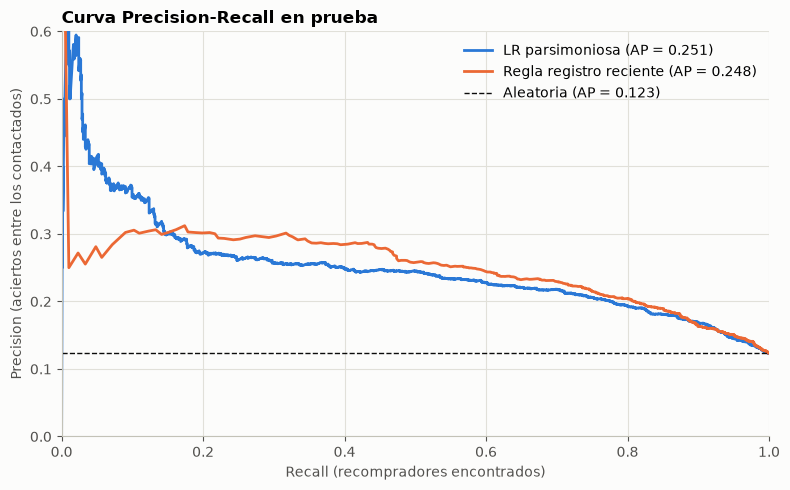

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
curvas = [
    (NOMBRE_SELECCIONADO, COLORES["modelo"], "-", 2),
    (REGLA["nombre"], COLORES["regla"], "-", 2),
]
for nombre, color, estilo, grosor in curvas:
    precision, recall, _ = precision_recall_curve(df_test[OBJETIVO], puntuaciones_test[nombre])
    ax.plot(recall, precision, color=color, linestyle=estilo, linewidth=grosor,
            label=f"{nombre} (AP = {resultados_test.loc[nombre, 'AP']:.3f})")
ax.axhline(prevalencia_test, color=COLORES["tinta"], linestyle="--", linewidth=1,
           label=f"Aleatoria (AP = {prevalencia_test:.3f})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.6)
ax.set_xlabel("Recall (recompradores encontrados)")
ax.set_ylabel("Precision (aciertos entre los contactados)")
ax.set_title("Curva Precision-Recall en prueba", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

El modelo y la regla quedan muy por encima de la referencia aleatoria (línea discontinua, 12,3%) en todo el rango de recall.

- **En el extremo superior del ranking** (el 2–3% de clientes con mayor puntuación), el modelo es más preciso: entre 35% y 40% de aciertos, frente a ~30% de la regla. Para campañas muy pequeñas y costosas, el modelo concentra mejor a los recompradores.
- **Con un recall de entre 20% y 60%**, la regla queda ligeramente por encima, lo que es consistente con el punto de operación del 30%.

#### 9.3. Priorización por deciles y calibración

Este es el gráfico más útil para el negocio. El panel izquierdo muestra la tasa real de recompra de cada decil de clientes ordenados por el modelo, junto a la probabilidad media predicha (calibración). El derecho muestra el porcentaje acumulado de recompradores que se captura al contactar a una fracción creciente de clientes.

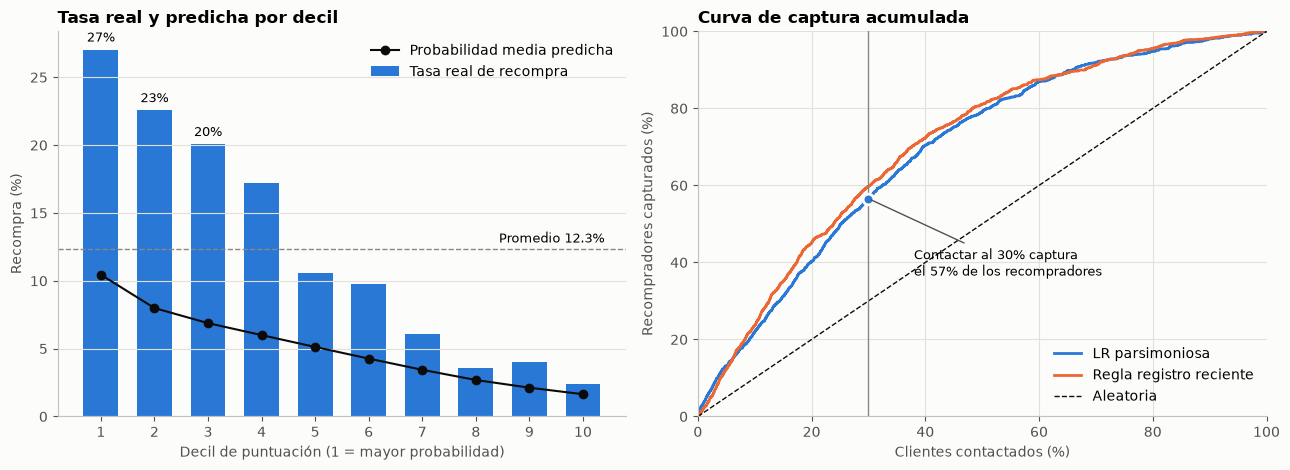

,clientes,recompradores,tasa_real,prob_media,captura_acumulada,lift
decil,,,,,,
1,873,236,0.270,0.104,0.220,2.194
2,873,197,0.226,0.080,0.403,1.832
3,872,175,0.201,0.069,0.566,1.629
4,873,150,0.172,0.060,0.705,1.395
5,872,92,0.106,0.051,0.791,0.856
6,873,85,0.097,0.043,0.870,0.790
7,873,53,0.061,0.034,0.919,0.493
8,872,31,0.036,0.027,0.948,0.289
9,873,35,0.040,0.021,0.980,0.325


In [14]:
def tabla_deciles(y_real, puntuacion):
    t = pd.DataFrame({"real": np.asarray(y_real), "prob": np.asarray(puntuacion)})
    t = t.sort_values("prob", ascending=False, kind="stable").reset_index(drop=True)
    t["decil"] = np.arange(len(t)) * 10 // len(t) + 1
    resumen = t.groupby("decil").agg(
        clientes=("real", "size"), recompradores=("real", "sum"),
        tasa_real=("real", "mean"), prob_media=("prob", "mean"),
    )
    resumen["captura_acumulada"] = resumen["recompradores"].cumsum() / t["real"].sum()
    resumen["lift"] = resumen["tasa_real"] / t["real"].mean()
    return resumen


def curva_captura(y_real, puntuacion):
    orden = np.argsort(-np.asarray(puntuacion), kind="stable")
    capturados = np.cumsum(np.asarray(y_real)[orden]) / np.sum(y_real)
    fraccion = np.arange(1, len(orden) + 1) / len(orden)
    return np.r_[0, fraccion], np.r_[0, capturados]


deciles = tabla_deciles(df_test[OBJETIVO], puntuaciones_test[NOMBRE_SELECCIONADO])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.bar(deciles.index, deciles["tasa_real"] * 100, color=COLORES["modelo"], width=0.65,
       label="Tasa real de recompra")
ax.plot(deciles.index, deciles["prob_media"] * 100, color=COLORES["tinta"], marker="o",
        markersize=6, linewidth=1.5, label="Probabilidad media predicha")
ax.axhline(prevalencia_test * 100, color=COLORES["contexto"], linestyle="--", linewidth=1)
ax.text(10.4, prevalencia_test * 100 + 0.5, f"Promedio {prevalencia_test:.1%}", ha="right", fontsize=9)
for decil in [1, 2, 3]:
    ax.text(decil, deciles.loc[decil, "tasa_real"] * 100 + 0.6,
            f"{deciles.loc[decil, 'tasa_real']:.0%}", ha="center", fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decil de puntuación (1 = mayor probabilidad)")
ax.set_ylabel("Recompra (%)")
ax.set_title("Tasa real y predicha por decil", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)

ax = axes[1]
for nombre, color in [(NOMBRE_SELECCIONADO, COLORES["modelo"]), (REGLA["nombre"], COLORES["regla"])]:
    x, y = curva_captura(df_test[OBJETIVO], puntuaciones_test[nombre])
    ax.plot(x * 100, y * 100, color=color, linewidth=2, label=nombre)
ax.plot([0, 100], [0, 100], color=COLORES["tinta"], linestyle="--", linewidth=1, label="Aleatoria")
pct = CONFIG["pct_contacto"]
captura = curva_captura(df_test[OBJETIVO], puntuaciones_test[NOMBRE_SELECCIONADO])[1][int(np.ceil(len(df_test) * pct))]
ax.axvline(pct * 100, color=COLORES["contexto"], linewidth=1)
ax.scatter([pct * 100], [captura * 100], s=60, color=COLORES["modelo"], edgecolor="#fcfcfb", linewidth=2, zorder=3)
ax.annotate(f"Contactar al {pct:.0%} captura\nel {captura:.0%} de los recompradores",
            (pct * 100, captura * 100), xytext=(pct * 100 + 8, captura * 100 - 20), fontsize=9,
            arrowprops={"arrowstyle": "-", "color": COLORES["tinta_2"]})
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("Clientes contactados (%)")
ax.set_ylabel("Recompradores capturados (%)")
ax.set_title("Curva de captura acumulada", loc="left")
ax.legend(frameon=False, loc="lower right")

plt.tight_layout()
plt.show()

display(deciles.round(3))

**Priorización.**

- El primer decil recompra un 27% (2,2 veces el promedio) y los tres primeros deciles, entre 20% y 27%.
- Contactar a ese 30% captura el **57% de los recompradores**. Ampliar al 40% subiría la captura al 70%.
- Los cuatro deciles inferiores recompran menos del 6%. Ahí una campaña costosa tendría poco retorno.

**Calibración.** La línea negra sigue el orden de las barras (el ranking es correcto), pero queda sistemáticamente por debajo: en el primer decil el modelo predice 10% cuando la tasa real es 27%. Para decidir *a quién* contactar, se usa el ranking. Para estimar *cuántas* recompras esperar, las probabilidades deben recalibrarse con el periodo más reciente.

#### 9.4. Matriz de confusión en el punto de operación

In [15]:
orden = np.argsort(-puntuaciones_test[NOMBRE_SELECCIONADO], kind="stable")
contactar = np.zeros(len(df_test), dtype=int)
contactar[orden[:int(np.ceil(len(df_test) * CONFIG["pct_contacto"]))]] = 1
real = df_test[OBJETIVO].to_numpy()

matriz = pd.DataFrame(
    [[((real == 1) & (contactar == 1)).sum(), ((real == 1) & (contactar == 0)).sum()],
     [((real == 0) & (contactar == 1)).sum(), ((real == 0) & (contactar == 0)).sum()]],
    index=["Recompra real", "No recompra real"],
    columns=["Contactado", "No contactado"],
)
display(matriz)

,Contactado,No contactado
Recompra real,608,467
No recompra real,2010,5641


Al contactar a 2.618 clientes (el 30% de prueba):

- **608 recompran** (precision 23,2%). Con una selección al azar del mismo tamaño se esperarían unos 320.
- **467 recompradores quedan fuera** de la campaña (falsos negativos). Están sobre todo en los deciles 4 a 6, con tasas del 10%–17%.
- **2.010 contactados no recompran** (falsos positivos).

Reducir los falsos negativos exige contactar a más clientes. Reducir los falsos positivos exige contactar a menos. El equilibrio depende del costo del contacto frente al margen de una recompra adicional, y por eso `pct_contacto` es un parámetro de negocio.

Con una señal débil y un 12% de positivos, una precision baja **no es un fallo del modelo, sino una característica del problema**. La pregunta relevante es cuánto mejor que el azar se elige a quién contactar: el doble.

### 10. Pipeline automatizado: reentrenamiento y predicciones

#### 10.1. Diseño

La función `ejecutar_pipeline` encadena todo el proceso sin pasos manuales. Usa la especificación de modelo seleccionada en la sección 8: en producción el modelo **no se vuelve a seleccionar** en cada ejecución, solo se reentrena.

1. **Carga y validación:** `cargar_tabla_modelo` + `validar_tabla_modelo`. Si falla un control bloqueante, el proceso se detiene.
2. **Fecha de corte:** `aplicar_fecha_corte` con `CONFIG["fecha_corte"]`.
3. **Control de calidad del modelo:** se entrena con la historia anterior al periodo más reciente y se mide en ese periodo, frente a la regla de referencia. Si el modelo no supera al orden aleatorio, se emite una alerta.
4. **Reentrenamiento:** con todos los clientes etiquetados hasta la fecha de corte.
5. **Predicción:** sobre los clientes cuya ventana de 60 días sigue abierta. Son los que el negocio todavía puede contactar.
6. **Persistencia idempotente:** los archivos se nombran con la fecha de corte y se sobrescriben. Reejecutar con el mismo corte reemplaza los resultados en lugar de duplicarlos.

**Salidas** en `outputs/`:

- `predicciones_AAAAMMDD.csv`: `user_id`, `probabilidad_recompra`, ranking, decil, prioridad, indicador de contacto, días restantes de la ventana y metadatos de trazabilidad.
- `modelo_recompra_<version>_AAAAMMDD.joblib`: pipeline entrenado, variables, configuración y métricas de control.

In [16]:
def generar_predicciones(modelo, spec, clientes, corte, cfg):
    """Puntua a los clientes cuya ventana de 60 dias sigue abierta."""
    if clientes.empty:
        raise ValueError("No hay clientes pendientes de puntuar con esta fecha de corte")

    pred = pd.DataFrame({
        "user_id": clientes["user_id"].to_numpy(),
        "probabilidad_recompra": puntuar(modelo, spec, clientes),
        "dias_restantes_ventana": (
            clientes["first_order_ts"] + pd.Timedelta(days=cfg["ventana_dias"]) - corte
        ).dt.days.to_numpy(),
    })
    pred = pred.sort_values(["probabilidad_recompra", "user_id"], ascending=[False, True])
    pred = pred.reset_index(drop=True)

    n = len(pred)
    pred["ranking"] = np.arange(1, n + 1)
    pred["decil"] = np.arange(n) * 10 // n + 1
    pred["prioridad"] = np.select(
        [pred["decil"] == 1, pred["decil"].isin([2, 3])], ["Alta", "Media"], default="Baja")
    pred["contactar"] = pred["ranking"] <= int(np.ceil(n * cfg["pct_contacto"]))
    pred["fecha_corte"] = corte.date().isoformat()
    pred["modelo_version"] = cfg["modelo_version"]
    pred["fecha_proceso"] = datetime.now(timezone.utc).isoformat(timespec="seconds")

    # Validaciones de salida
    assert len(pred) == len(clientes)
    assert pred["user_id"].is_unique
    assert pred["probabilidad_recompra"].between(0, 1).all()
    assert pred["dias_restantes_ventana"].between(0, cfg["ventana_dias"]).all()
    return pred


def guardar_resultados(pred, artefacto, corte, cfg):
    """Escritura idempotente: un archivo por fecha de corte, sobrescrito al reejecutar."""
    destino = Path(cfg["dir_salidas"])
    destino.mkdir(parents=True, exist_ok=True)
    sufijo = corte.strftime("%Y%m%d")
    ruta_pred = destino / f"predicciones_{sufijo}.csv"
    ruta_modelo = destino / f"modelo_recompra_{cfg['modelo_version']}_{sufijo}.joblib"
    pred.to_csv(ruta_pred, index=False, float_format="%.6f")
    joblib.dump(artefacto, ruta_modelo)
    return ruta_pred, ruta_modelo


def ejecutar_pipeline(cfg, spec_modelo, guardar=True):
    """Proceso completo: datos -> validacion -> control del modelo -> reentrenamiento -> predicciones."""
    # 1-2. Datos
    df_bruto = cargar_tabla_modelo(cfg)
    validar_tabla_modelo(df_bruto, cfg)
    datos, corte = aplicar_fecha_corte(df_bruto, cfg)
    etiquetados = datos.loc[datos["has_full_60d_history"] == 1].copy()
    etiquetados[OBJETIVO] = etiquetados[OBJETIVO].astype(int)
    pendientes = datos.loc[datos["has_full_60d_history"] == 0]

    # 3. Control de calidad del modelo en el periodo mas reciente
    dev, test, inicio_test = particion_temporal(etiquetados, cfg)
    control = {}
    for spec in [spec_modelo, REGLA]:
        modelo = ajustar(spec, dev, inicio_test, cfg)
        control[spec["nombre"]] = metricas(
            test[OBJETIVO], puntuar(modelo, spec, test), cfg, spec["probabilistico"])
    if control[spec_modelo["nombre"]]["Lift AP"] <= 1:
        warnings.warn("El modelo no supera al orden aleatorio en el periodo de control")

    # 4. Reentrenamiento con todos los clientes etiquetados
    modelo_final = ajustar(spec_modelo, etiquetados, corte, cfg)

    # 5. Predicciones
    pred = generar_predicciones(modelo_final, spec_modelo, pendientes, corte, cfg)

    # 6. Persistencia
    artefacto = {
        "pipeline": modelo_final,
        "nombre_modelo": spec_modelo["nombre"],
        "variables": spec_modelo["variables"],
        "fecha_corte": corte,
        "clientes_entrenamiento": len(etiquetados),
        "metricas_control": control,
        "config": {k: str(v) if isinstance(v, Path) else v for k, v in cfg.items()},
    }
    rutas = guardar_resultados(pred, artefacto, corte, cfg) if guardar else (None, None)

    return {
        "fecha_corte": corte.date().isoformat(),
        "clientes_entrenamiento": len(etiquetados),
        "clientes_puntuados": len(pred),
        "lift_ap_control_modelo": round(control[spec_modelo["nombre"]]["Lift AP"], 3),
        "lift_ap_control_regla": round(control[REGLA["nombre"]]["Lift AP"], 3),
        "archivo_predicciones": rutas[0],
        "archivo_modelo": rutas[1],
        "predicciones": pred,
    }

#### 10.2. Ejecución con la configuración por defecto

In [17]:
resultado = ejecutar_pipeline(CONFIG, SPEC_FINAL)
predicciones = resultado.pop("predicciones")
display(pd.Series(resultado, name="Valor").to_frame())
display(predicciones.head(10))

,Valor
fecha_corte,2025-02-14
clientes_entrenamiento,58167
clientes_puntuados,8002
lift_ap_control_modelo,2.034
lift_ap_control_regla,2.016
archivo_predicciones,D:\Caso_Practico\outputs\predicciones_20250214...
archivo_modelo,D:\Caso_Practico\outputs\modelo_recompra_1.0_2...


,user_id,probabilidad_recompra,dias_restantes_ventana,ranking,decil,prioridad,contactar,fecha_corte,modelo_version,fecha_proceso
0,99532,0.648376,57,1,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
1,17158,0.593884,57,2,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
2,98455,0.537787,57,3,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
3,92597,0.529286,58,4,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
4,98300,0.520591,58,5,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
5,46716,0.505213,58,6,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
6,8630,0.474574,57,7,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
7,55756,0.473010,55,8,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
8,73996,0.469134,59,9,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00
9,73102,0.468910,59,10,1,Alta,True,2025-02-14,1.0,2026-10-26T06:03:39+00:00


#### 10.3. Reejecución: idempotencia y fecha de corte configurable

Se comprueban las dos propiedades que pide el caso:

1. **Reejecutar con la misma fecha de corte no duplica resultados.** Se sobrescribe el mismo archivo con los mismos clientes y las mismas probabilidades.
2. **La fecha de corte es un parámetro.** Se simula el proceso tal como se habría ejecutado el 30/06/2024, sin guardar resultados. En ese caso se entrena solo con la historia disponible entonces y se puntúa a los clientes cuya ventana estaba abierta ese día.

In [18]:
# 1. Reejecucion con la misma configuracion
segunda = ejecutar_pipeline(CONFIG, SPEC_FINAL)
releido = pd.read_csv(segunda["archivo_predicciones"])
archivos = sorted(p.name for p in Path(CONFIG["dir_salidas"]).glob("predicciones_*.csv"))

assert segunda["archivo_predicciones"] == resultado["archivo_predicciones"]
assert len(releido) == len(predicciones) and releido["user_id"].is_unique
assert np.allclose(
    releido.set_index("user_id")["probabilidad_recompra"].sort_index(),
    predicciones.set_index("user_id")["probabilidad_recompra"].sort_index(), atol=1e-6)
print("Reejecucion idempotente: mismo archivo, mismas filas y mismas probabilidades.")
print("Archivos de predicciones en outputs/:", archivos)

# 2. Simulacion con una fecha de corte anterior
config_historica = {**CONFIG, "fecha_corte": "2024-06-30"}
historico = ejecutar_pipeline(config_historica, SPEC_FINAL, guardar=False)
historico.pop("predicciones")
display(pd.DataFrame({"Corte por defecto": resultado, "Corte 2024-06-30": historico}))

Reejecucion idempotente: mismo archivo, mismas filas y mismas probabilidades.
Archivos de predicciones en outputs/: ['predicciones_20250214.csv']


,Corte por defecto,Corte 2024-06-30
fecha_corte,2025-02-14,2024-06-30
clientes_entrenamiento,58167,42498
clientes_puntuados,8002,3447
lift_ap_control_modelo,2.034,1.696
lift_ap_control_regla,2.016,1.542
archivo_predicciones,D:\Caso_Practico\outputs\predicciones_20250214...,None
archivo_modelo,D:\Caso_Practico\outputs\modelo_recompra_1.0_2...,None


**Resultados:**

1. **Idempotencia.** La segunda ejecución reescribe `predicciones_20250214.csv` con los mismos 8.002 clientes y las mismas probabilidades. Solo cambia `fecha_proceso`, que registra la última ejecución.
2. **Fecha de corte configurable.** Con corte el 30/06/2024, el pipeline entrena con 42.498 clientes y puntúa a 3.447 clientes con la ventana abierta en esa fecha, sin usar información posterior. En ese periodo de control, el modelo **supera** a la regla (lift de AP 1,70 frente a 1,54). Con el corte actual, ambos empatan (2,03 frente a 2,02).

La ventaja del modelo sobre la regla depende del periodo. Por eso el pipeline registra en cada ejecución las métricas de control de ambos, como base para un esquema *champion/challenger* en producción.

**Clientes puntuados.** Son los 8.002 clientes cuya primera compra ocurrió en los últimos 60 días antes del corte. El archivo incluye su prioridad comercial y los días que les quedan de ventana. En producción, convendría excluir a quienes ya hicieron su segunda compra, cruzando con `orders` antes de lanzar la campaña. La tabla analítica no conserva ese dato para los clientes sin etiqueta.

### 11. Conclusiones y recomendaciones

#### 11.1. Resultados principales

| Indicador (periodo de prueba, ago–dic 2024) | Aleatoria | Regla registro reciente | Modelo (LR parsimoniosa) |
|---|---:|---:|---:|
| Average Precision | 0,127 | 0,248 | **0,251** |
| Precision contactando al 30% | 12,2% | 24,5% | 23,2% |
| Recall contactando al 30% | 29,6% | 59,7% | 56,6% |
| Tasa de recompra del primer decil | 12,7% | 29,0% | 27,0% |

1. **La recompra a 60 días es poco frecuente (5,6%) y difícil de predecir** con la información disponible en la primera compra.
2. **La señal se concentra en la antigüedad del cliente.** Quienes compran en su primera semana tras registrarse recompran 6,6 veces más que los registrados hace más de dos años. La cesta, la categoría, la navegación y los datos demográficos aportan poco.
3. **La tasa crece con cada cohorte de registro**, de ~2,5% en 2019 a 17% en 2024. Esto explica el cambio de distribución entre entrenamiento y prueba.
4. **El modelo final duplica la eficacia de una selección al azar.** Es el mejor de los candidatos evaluados y empata con una regla simple basada en la antigüedad. Su principal valor práctico es **ordenar a los clientes para priorizar campañas**.

#### 11.2. Recomendaciones de negocio

1. **Campaña de segunda compra para el 30% priorizado** (prioridad Alta y Media). Captura el 57% de los recompradores con el doble de efectividad que una selección al azar. El primer contacto debe ser en la primera semana tras la compra y el recordatorio, hacia la mitad de la ventana (`dias_restantes_ventana`).
2. **Onboarding para clientes que compran poco después de registrarse.** Son el segmento más receptivo (14%–18% de recompra en los primeros 30 días desde el registro). Un recorrido de bienvenida con incentivo a la segunda compra es la palanca más directa.
3. **Contactos de bajo costo para los deciles inferiores** (tasa menor al 6%), por ejemplo email sin incentivo, para no invertir donde el retorno esperado es bajo.
4. **Medir el impacto con un grupo de control.** El modelo identifica a quién es más probable que recompre, no a quién cambia de comportamiento al recibir una campaña. Reservar un grupo de control aleatorio dentro de los deciles priorizados permite medir el efecto incremental real.
5. **Investigar el efecto de cohorte.** Si responde a cambios reales en la captación o el onboarding de 2023–2024, entender qué cambió es más valioso que cualquier mejora del modelo.

#### 11.3. Limitaciones

- **Señal débil.** El modelo no supera de forma consistente a la regla basada en la antigüedad. Se mantiene la regla como referencia permanente.
- **Calibración bajo cambio de distribución.** Las probabilidades subestiman la tasa real cuando esta crece entre cohortes. Para decidir se usa el ranking. Las probabilidades absolutas requieren recalibración periódica.
- **Disponibilidad temporal de variables.** Las variables de la cesta asumen que su contenido se conoce al confirmar la compra. Los estados de las órdenes y los atributos de usuario son instantáneas actuales, no históricas (sección 4.6).
- **Selección de variables y backtest.** Se usaron los mismos bloques para ambas cosas, por lo que el backtest de la LR parsimoniosa es algo optimista. La prueba final no se usó en ninguna decisión.
- **Clientes ya recompradores.** Los clientes con la ventana abierta pueden haber recomprado antes del corte. Deben excluirse en la activación de la campaña.

#### 11.4. Sugerencia de Próximos pasos

1. **Recalibración periódica** de las probabilidades con el trimestre etiquetado más reciente, y monitoreo de la tasa predicha frente a la real por cohorte.
2. **Esquema *champion/challenger*** con la regla como referencia: el pipeline ya registra las métricas de ambos en cada ejecución.
3. **Variables de comportamiento temprano** (navegación y emails en los primeros 7 días tras la compra), moviendo el momento de predicción unos días si el negocio lo permite.
4. **Modelos de *uplift*** una vez existan datos de campañas con grupo de control.

## Parte 3. Arquitectura cloud en AWS

### 12. Arquitectura propuesta

#### 12.1. Principios de diseño

El objetivo es llevar a producción el proceso de este notebook de forma **simple, programada y monitoreada**, asumiendo que los datos fuente llegan a Amazon S3.

1. **Servicios gestionados y de pago por uso.** El volumen actual es pequeño: 66 mil clientes, y el pipeline completo tarda menos de un minuto. No se justifican clústeres permanentes. Los servicios elegidos escalan sin cambios de diseño si el volumen crece.
2. **Reutilizar lo construido, sin reescribirlo.**
   - Las consultas de las secciones 1–4 se ejecutan en Amazon Athena, el equivalente SQL serverless de BigQuery.
   - Las funciones de Python de las secciones 5–10 se empaquetan en un contenedor.
3. **Las mismas garantías que el notebook:**
   - La fecha de corte es un parámetro de cada ejecución.
   - Los controles de calidad bloquean el proceso si fallan.
   - Las salidas se escriben por fecha de corte, sobrescribiendo, por lo que reejecutar no duplica resultados.
4. **Separación de frecuencias.** La predicción es diaria y el reentrenamiento, mensual (apartado 12.4).

#### 12.2. Diagrama de alto nivel

El diagrama se genera con `docs/diagrama_arquitectura.py` y está disponible en `docs/arquitectura_aws.png`. Los números corresponden a los componentes descritos en el apartado 12.3.

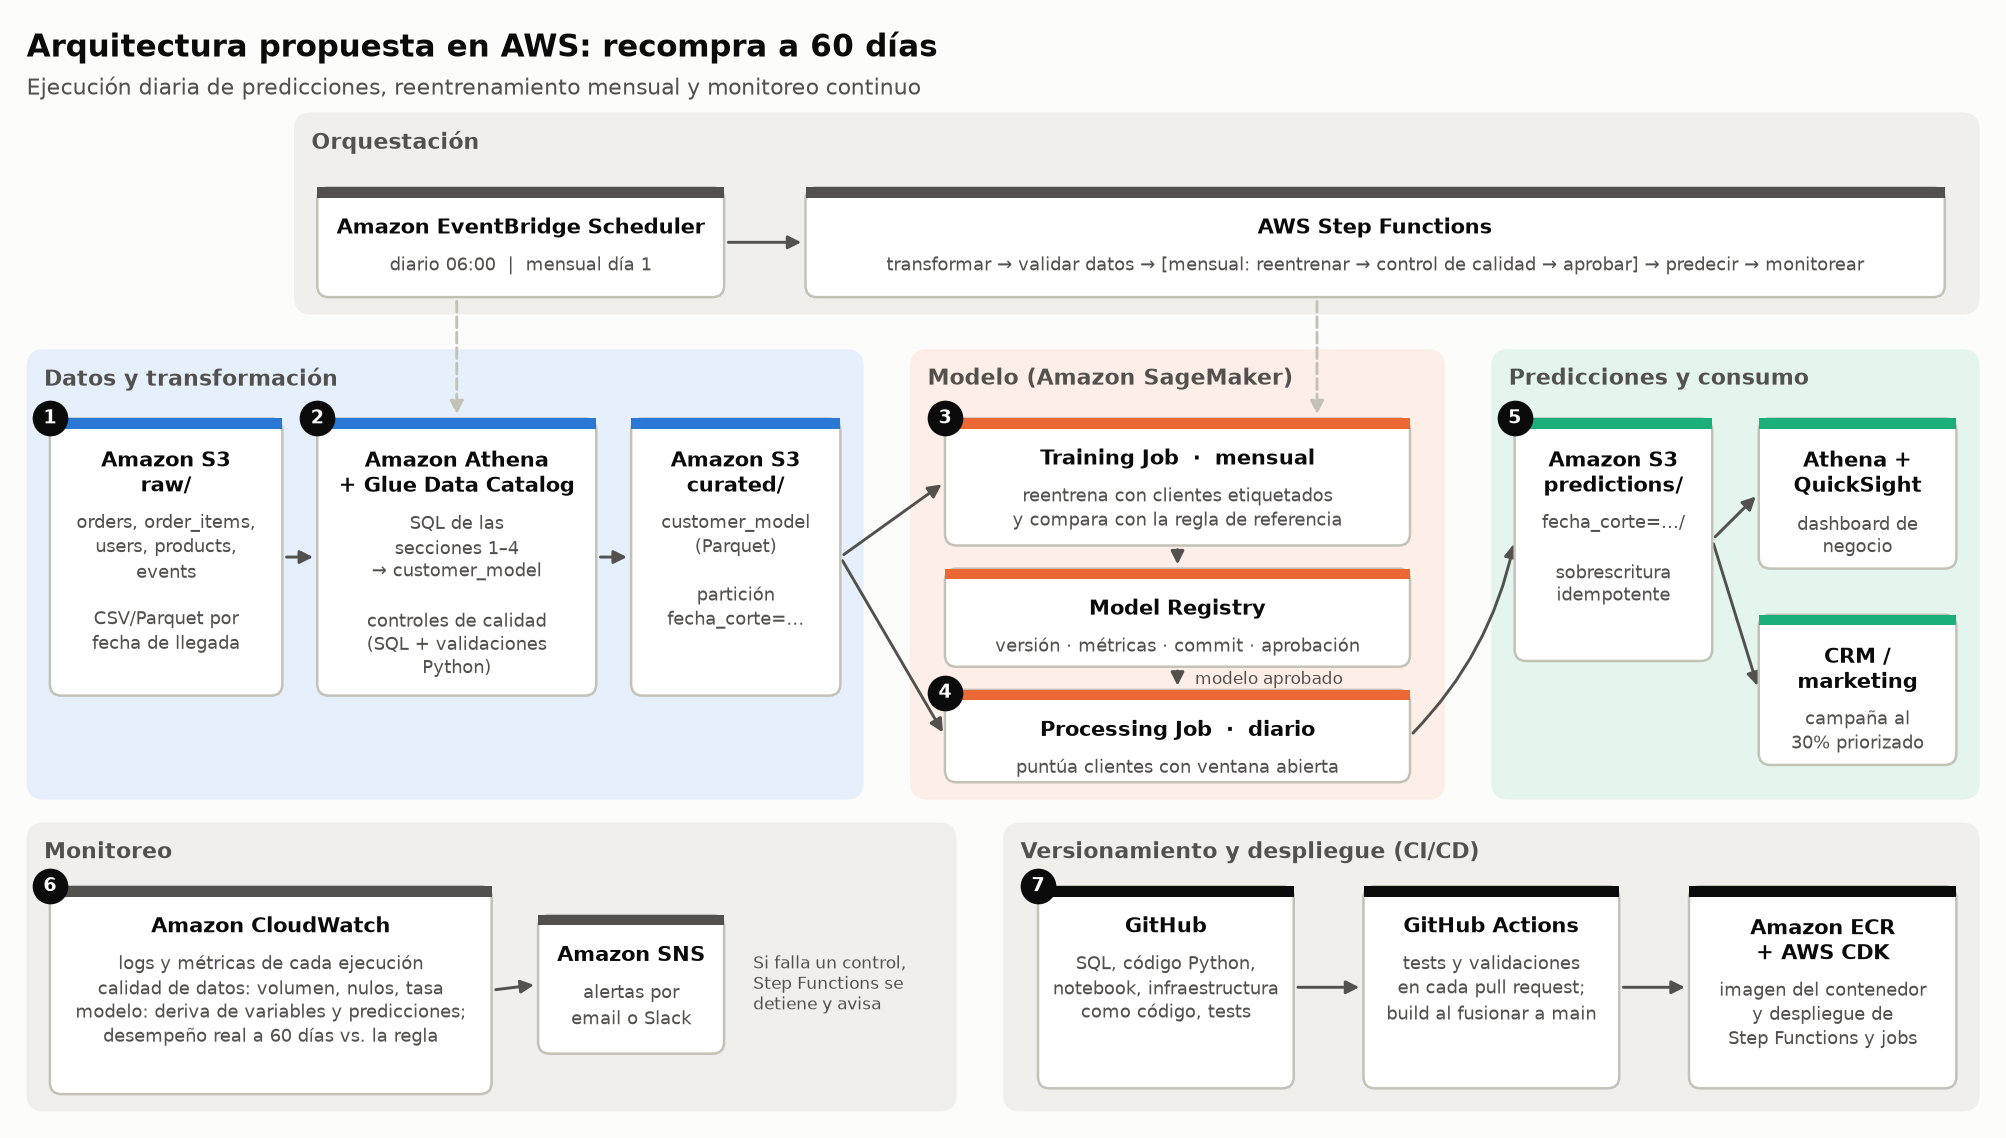

In [19]:
from IPython.display import Image, display

display(Image(filename=str(RAIZ / "docs" / "arquitectura_aws.png"), width=1100))

#### 12.3. Componentes: carga, transformación, modelo y predicciones

| # | Componente | Qué hace | Por qué |
|---|---|---|---|
| 1 | **Amazon S3 `raw/`** | Recibe los archivos fuente (`orders`, `order_items`, `users`, `products`, `events`), particionados por fecha de llegada. No se modifican. | Punto de entrada definido por el caso. Conserva la historia para reprocesar cualquier fecha |
| 2 | **Amazon Athena + AWS Glue Data Catalog** | El catálogo registra las tablas de S3. Athena ejecuta el SQL de las secciones 1–4 y escribe `customer_model` en `curated/` como Parquet particionado por `fecha_corte`. A continuación se ejecutan los controles de calidad: las consultas de validación de la sección 4.5 y `validar_tabla_modelo` | SQL serverless, sin infraestructura que administrar; se paga por datos leídos y Parquet reduce ese volumen |
| 3 | **SageMaker Training Job** (mensual) | Ejecuta los pasos de control y reentrenamiento de `ejecutar_pipeline`: mide el modelo frente a la regla de referencia en el periodo más reciente, lo reentrena con todos los clientes etiquetados y lo registra en el **Model Registry** con sus métricas, la fecha de corte y el commit de Git | Máquina efímera: solo cuesta mientras entrena. El registro deja trazabilidad de cada versión y controla qué modelo se usa |
| 4 | **SageMaker Processing Job** (diario) | Carga el último modelo aprobado y puntúa a los clientes con la ventana de 60 días abierta, excluyendo a quienes ya recompraron | Mismo contenedor que el entrenamiento, con otro punto de entrada |
| 5 | **Amazon S3 `predictions/`** | Guarda las predicciones por fecha de corte; se consultan con Athena | Ver el apartado 12.5 |
| 6 | **Amazon CloudWatch + Amazon SNS** | Registran logs y métricas y envían alertas | Ver el apartado 12.6 |
| 7 | **GitHub + GitHub Actions + Amazon ECR + AWS CDK** | Versionan el código, lo prueban y lo despliegan | Ver el apartado 12.7 |

**Adaptación del SQL de BigQuery a Athena.** Athena usa el dialecto de Trino. La lógica se mantiene y los cambios son de sintaxis:

| BigQuery | Athena |
|---|---|
| `TIMESTAMP_ADD(ts, INTERVAL 60 DAY)` | `date_add('day', 60, ts)` |
| `TIMESTAMP_DIFF(a, b, DAY)` | `date_diff('day', b, a)` |
| `COUNTIF(condición)` | `count_if(condición)` |
| `ARRAY_AGG(x ORDER BY y DESC LIMIT 1)[SAFE_OFFSET(0)]` | `max_by(x, y)` |
| `QUALIFY ROW_NUMBER() OVER (...) = 1` | Subconsulta con `ROW_NUMBER()` filtrada en el `WHERE` (Athena no admite `QUALIFY`) |

#### 12.4. Ejecución programada, reentrenamiento y predicciones

**Amazon EventBridge Scheduler** lanza una máquina de estados de **AWS Step Functions** que coordina todos los pasos. Step Functions se integra de forma nativa con Athena y SageMaker, reintenta los pasos que fallan y se detiene con una alerta si un control no se cumple.

| Proceso | Frecuencia | Justificación |
|---|---|---|
| Transformar → validar datos → predecir → monitorear | **Diaria** | Cada día hay clientes nuevos con su primera compra, y el 27% de las recompras ocurre en los primeros 15 días (sección 6.3). Hay que puntuarlos y contactarlos cuanto antes |
| Reentrenar → control de calidad → aprobar | **Mensual**, antes de la predicción del día 1 | Las etiquetas maduran 60 días después de cada primera compra, y la tasa cambia entre cohortes (sección 6.2). Un mes equilibra la actualización con estabilidad, y entrenar cuesta menos de un minuto de cómputo |
| Reentrenamiento extraordinario | Cuando lo indica el monitoreo | Deriva de datos o desempeño por debajo de la regla de referencia |

**Aprobación del modelo.** Un modelo nuevo se aprueba automáticamente solo si:

- su lift de AP en el periodo de control es mayor que 1, es decir, supera al orden aleatorio, y
- no es inferior al del modelo vigente.

Si no cumple ambas condiciones, se mantiene el modelo vigente y se envía una alerta para revisión. Es la misma lógica de control que `ejecutar_pipeline` (sección 10).

**Idempotencia.** Cada ejecución recibe su `fecha_corte` y sobrescribe la partición correspondiente en `curated/` y `predictions/`. Repetir un día, por ejemplo tras un fallo, reemplaza los resultados en lugar de duplicarlos. Reprocesar una fecha pasada es lanzar la máquina de estados con esa fecha.

#### 12.5. Dónde se guardan las predicciones para el negocio

- **Almacenamiento:** `s3://…/predictions/fecha_corte=AAAA-MM-DD/`, en Parquet, con las columnas del archivo de la sección 10. Incluye `user_id`, `probabilidad_recompra`, `decil`, `prioridad`, `contactar` y `dias_restantes_ventana`, además de la versión del modelo y el commit.
- **Consulta:** la tabla está registrada en el Glue Data Catalog. Una vista de Athena, `predicciones_vigentes`, expone siempre la última fecha de corte.
- **Consumo:**
  - **Amazon QuickSight** muestra un dashboard con clientes priorizados, distribución por decil y resultados de campañas anteriores.
  - Una exportación diaria de los clientes con `contactar = True` alimenta la herramienta de CRM o marketing.
- **Historia:** las particiones anteriores se conservan. Al cerrarse la ventana de 60 días, se cruzan con las recompras reales para medir el desempeño del modelo y de las campañas (apartado 12.6).

#### 12.6. Monitoreo de calidad de datos y del modelo

Cada paso publica métricas en **Amazon CloudWatch**. Las alarmas notifican por **Amazon SNS** (email o Slack).

| Ámbito | Qué se mide | Frecuencia | Acción si falla |
|---|---|---|---|
| **Calidad de datos** | Llegada de los archivos del día; volumen de filas frente al histórico; nulos y duplicados en claves; registros sin correspondencia; controles de `validar_tabla_modelo` (etiqueta coherente con el corte, rangos, tasa de recompra plausible) | Diaria | Step Functions se detiene antes de predecir y avisa. Se conserva la última predicción válida |
| **Deriva de variables** | Índice de estabilidad poblacional (PSI) de las variables principales (`days_since_signup`, actividad web, `traffic_source`) frente a los datos de entrenamiento | Diaria | Alerta si el PSI supera 0,2 |
| **Deriva de predicciones** | Probabilidad media y distribución por decil | Diaria | Alerta si se desvía del rango habitual |
| **Desempeño real** | Cuando cierra la ventana de 60 días: AP, precision y recall al 30%, lift frente a la regla de referencia y calibración (probabilidad predicha frente a tasa real, por cohorte) | Mensual | Si el modelo queda por debajo de la regla dos meses seguidos, o la calibración se desvía, se reentrena y revisa |
| **Operación** | Duración, fallos y costo de cada ejecución | Cada ejecución | Alerta inmediata ante cualquier fallo |

El monitoreo del desempeño real responde a dos hallazgos del análisis:

- El **efecto de cohorte** desplaza la tasa de recompra con el tiempo y afecta a la calibración (sección 9.3).
- La **ventaja del modelo frente a la regla** varía según el periodo (sección 10.3).

#### 12.7. Versionamiento del código con GitHub

**Estructura propuesta del repositorio en producción:**

```
├── sql/            # consultas de transformación y validación
├── src/recompra/   # funciones del notebook como paquete: datos, modelo, pipeline
├── notebooks/      # análisis exploratorio y documentación (este notebook)
├── tests/          # pruebas de validaciones y del pipeline con datos de muestra
├── infra/          # AWS CDK: Step Functions, jobs de SageMaker, permisos
└── Dockerfile      # imagen única para entrenamiento y predicción
```

**Flujo de trabajo:**

1. **Desarrollo:** cada cambio se hace en una rama y se propone mediante *pull request* con revisión.
2. **Integración continua (GitHub Actions):** en cada *pull request* se ejecutan el análisis estático del código, las pruebas unitarias y el pipeline completo sobre una muestra de datos.
3. **Despliegue continuo:** al fusionar a `main`, se construye la imagen y se publica en **Amazon ECR** etiquetada con el commit. **AWS CDK** despliega la infraestructura, primero en un entorno de pruebas y después en producción tras una aprobación manual.
4. **Seguridad:** GitHub Actions se autentica en AWS con OIDC, sin credenciales permanentes. Cada servicio usa un rol de IAM con permisos mínimos.

**Trazabilidad:** cada modelo del Model Registry guarda el commit, la etiqueta de la imagen y la fecha de corte de entrenamiento. Así, cualquier predicción se puede rastrear hasta el código y los datos que la generaron.

Los datos y los modelos entrenados no se versionan en Git. Viven en S3 y en el Model Registry.

#### 12.8. Integración con Snowflake (opcional)

Como se solicita Snowflake, la arquitectura se adapta cambiando solo los componentes 2 y 5. Snowflake pasa a ser la plataforma de datos, SageMaker sigue a cargo del modelo y S3 actúa como zona de intercambio.

| Paso | Con Snowflake |
|---|---|
| **Carga** | `raw/` se define como *external stage*. **Snowpipe** carga automáticamente cada archivo nuevo en tablas de Snowflake |
| **Transformación y calidad** | El SQL de las secciones 1–4 se ejecuta en Snowflake, con las adaptaciones de sintaxis de la sección 4.7, en lugar de Athena. Step Functions lo lanza, o lo hacen *Tasks* de Snowflake |
| **Modelo** | `customer_model` se descarga a `curated/` en Parquet (`COPY INTO @stage`). El entrenamiento y la predicción en SageMaker no cambian |
| **Predicciones** | Se cargan de vuelta en una tabla `predicciones_recompra` de Snowflake, donde el negocio las consulta con sus herramientas habituales de BI |

Así se aprovecha la plataforma que el cliente ya gobierna sin acoplar el modelo a ella. Una alternativa es entrenar dentro de Snowflake con **Snowpark ML**. Elimina el intercambio por S3, pero ata el ciclo de vida del modelo a Snowflake; tiene sentido si el equipo prefiere centralizar todo allí.

#### 12.9. Equivalencias con Google Cloud

El desarrollo del caso se hizo en BigQuery. Si la solución se desplegara en Google Cloud, los componentes equivalentes serían:

| Función | AWS (propuesta) | Google Cloud |
|---|---|---|
| Almacenamiento de archivos | Amazon S3 | Cloud Storage |
| SQL y catálogo | Athena + Glue Data Catalog | BigQuery |
| Programación | EventBridge Scheduler | Cloud Scheduler |
| Orquestación | Step Functions | Workflows / Cloud Composer |
| Entrenamiento, predicción y registro de modelos | SageMaker | Vertex AI |
| Dashboard | QuickSight | Looker Studio |
| Monitoreo y alertas | CloudWatch + SNS | Cloud Monitoring + Pub/Sub |
| Registro de imágenes | ECR | Artifact Registry |